# Graphical maximum entropy from reversible atom exchanges

This notebook gives a constructive Wallis/Jaynes demonstration for a six-sided die. Every empirical result is produced by **constraint-preserving exchanges**, not by entropy optimization. A macrostate is a six-count vector, while the tracked microscopic state consists of $D$ labeled atoms: select an ordered block of distinct atoms uniformly, then replace its ordered labels uniformly within the same constraint signature.

For block size $k$, a particular microscopic proposal and its reverse both have probability

$$
\frac{w_k}{(D)_k}\,\frac{1}{|\mathcal P_k(T)|}.
$$

Thus the microscopic chain is reversible with respect to the uniform distribution on each connected component. The count-level chain inherits macrostate weight

$$W(n)=\frac{D!}{\prod_i n_i!}, \qquad \log W(n)=D H(n/D)+O(\log D).$$

Every valid proposal is accepted, self-loops are retained, and entropy is measured only afterward as a consequence of mixing. The analytical MaxEnt distributions are independent theoretical benchmarks; they never determine proposal acceptance or the reported final exchange state.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Locate the repository whether execution starts at its root or beside this notebook.
REPO_ROOT = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "pyproject.toml").exists()
)

from graphical_sampling.maxent import (
    MomentConstraints,
    ReplacementKernel,
    design_probability_mass,
    distribution_diagnostics,
    find_feasible_counts,
    run_chain,
    run_design_exchanges,
    solve_discrete_maxent,
)

plt.style.use("seaborn-v0_8-white")
plt.rcParams["axes.grid"] = False
OUTCOMES = np.arange(1, 7, dtype=int)


In [2]:
# One authoritative parameter cell for the complete reproducible study.
SETTINGS = {
    "write_outputs": True,
    "output_dir": "simulations/results/graphical_maxent_die",
    "replay_iterations": 250,
    "experiments": {
        "unconstrained": {
            "D": 10_000,
            "iterations": 200_000,
            "burn_in": 100_000,
            "checkpoint_every": 1_000,
            "seed": 20_260_921,
        },
        "mean": {
            "D": 10_000,
            "iterations": 400_000,
            "burn_in": 200_000,
            "checkpoint_every": 2_000,
            "seed": 20_260_922,
        },
        "two_moment": {
            "D": 20_000,
            "iterations": 1_000_000,
            "burn_in": 500_000,
            "checkpoint_every": 5_000,
            "seed": 20_260_923,
        },
    },
    "finite_population": {
        "exchanges": 10_000,
        "seed": 20_260_924,
        "checkpoint_every": 100,
        "partitions": 1,
        "pull_strategy": "default",
        "exchange_coef": 0.75,
    },
    "continuous": {
        "D": 6_000,
        "iterations": 150_000,
        "burn_in": 50_000,
        "checkpoint_every": 500,
        "replicates": 8,
        "seed": 20_260_925,
    },
}


## Exact constraints and independent MaxEnt benchmarks

The package solves each exponential-family moment equation independently of the Markov chain. The three signatures are empty, $\sum x$, and $(\sum x,\sum x^2)$.

In [3]:
CONSTRAINTS = {
    "unconstrained": MomentConstraints.from_moments(OUTCOMES, [], []),
    "mean": MomentConstraints.from_moments(OUTCOMES, [OUTCOMES], [4.0]),
    "two_moment": MomentConstraints.from_moments(
        OUTCOMES, [OUTCOMES, OUTCOMES**2], [4.0, 17.8475]
    ),
}
BENCHMARKS = {
    key: solve_discrete_maxent(constraints)
    for key, constraints in CONSTRAINTS.items()
}

for key, benchmark in BENCHMARKS.items():
    residual = CONSTRAINTS[key].features @ benchmark - CONSTRAINTS[key].targets
    assert np.max(np.abs(residual), initial=0.0) < 1e-10

benchmark_table = pd.DataFrame(BENCHMARKS, index=OUTCOMES)
benchmark_table.index.name = "die face"
display(benchmark_table.style.format("{:.10f}"))


,unconstrained,mean,two_moment
die face,,,
1,0.1666666667,0.1030652452,0.0410316102
2,0.1666666667,0.1227305335,0.1083937108
3,0.1666666667,0.1461480427,0.2007735633
4,0.1666666667,0.1740337124,0.2607509432
5,0.1666666667,0.2072400869,0.2374445294
6,0.1666666667,0.2467823792,0.1516056431


## Integer feasibility and the parity obstruction

For the two-moment target at $D=10{,}000$, the first-moment total is 40,000 (even) while the required second-moment total is 178,475 (odd). Since $x^2\equiv x\pmod 2$, no integer counts can satisfy both totals. We verify that the integer solver rejects this case. At the configured feasible $D$, a deterministic cubic objective supplies a deliberately sparse, non-MaxEnt starting point.

In [4]:
two_moment_constraints = CONSTRAINTS["two_moment"]
first_total_10000 = 40_000
second_total_10000 = 178_475
assert first_total_10000 % 2 != second_total_10000 % 2

d10000_infeasible = False
try:
    find_feasible_counts(two_moment_constraints, 10_000, objective=OUTCOMES**3)
except ValueError:
    d10000_infeasible = True
assert d10000_infeasible

two_moment_D = SETTINGS["experiments"]["two_moment"]["D"]
initial_two_moment = find_feasible_counts(
    two_moment_constraints, two_moment_D, objective=OUTCOMES**3
)
two_moment_constraints.validate_counts(initial_two_moment)
print(f"D=10,000 infeasible by parity: {d10000_infeasible}")
print(f"Sparse feasible start for D={two_moment_D:,}: {initial_two_moment.tolist()}")


D=10,000 infeasible by parity: True
Sparse feasible start for D=20,000: [3079, 0, 1, 7682, 9238, 0]


## Reusable experiment and checkpoint diagnostics

`run_chain(..., track_atoms=True)` executes the real microscopic atom process and retains its actual initial and final atom arrangements. Replacement patterns are uniform within an exact signature group and include the source pattern, so unchanged proposals remain explicit self-loops. “Count-changing rate” below means changed count vectors divided by all proposals; every constraint-valid microscopic proposal itself is accepted.

In [5]:
def checkpoint_frame(chain, constraints, benchmark):
    rows = []
    D = int(chain.final_counts.sum())
    for iteration, counts in zip(chain.checkpoint_iterations, chain.checkpoint_counts):
        constraints.validate_counts(counts)
        diagnostic = distribution_diagnostics(counts, constraints, benchmark=benchmark)
        row = {
            "iteration": int(iteration),
            **{f"count_{face}": int(counts[face - 1]) for face in OUTCOMES},
            **{f"p_{face}": counts[face - 1] / D for face in OUTCOMES},
            "entropy": diagnostic["entropy"],
            "L1": diagnostic["L1"],
            "mean": diagnostic["mean"],
            "variance": diagnostic["variance"],
            "max_constraint_residual": float(
                np.max(np.abs(diagnostic["constraint_residuals"]), initial=0.0)
            ),
        }
        rows.append(row)
    return pd.DataFrame(rows)


def execute_experiment(key, name, initial_counts, block_weights):
    config = SETTINGS["experiments"][key]
    constraints = CONSTRAINTS[key]
    benchmark = BENCHMARKS[key]
    kernel = ReplacementKernel(constraints, block_weights)
    chain = run_chain(
        initial_counts,
        constraints,
        kernel,
        iterations=config["iterations"],
        seed=config["seed"],
        checkpoint_every=config["checkpoint_every"],
        burn_in=config["burn_in"],
        track_atoms=True,
    )
    assert chain.initial_atoms is not None
    assert chain.final_atoms is not None
    atom_counts = np.array(
        [np.count_nonzero(chain.final_atoms == value) for value in constraints.outcomes],
        dtype=np.int64,
    )
    np.testing.assert_array_equal(atom_counts, chain.final_counts)
    trace = checkpoint_frame(chain, constraints, benchmark)
    initial_diagnostic = distribution_diagnostics(
        initial_counts, constraints, benchmark=benchmark
    )
    final_diagnostic = distribution_diagnostics(
        chain.final_counts, constraints, benchmark=benchmark
    )
    post_burn = chain.checkpoint_counts[chain.checkpoint_iterations >= config["burn_in"]]
    post_burn_probability = post_burn.mean(axis=0) / config["D"]

    replay_iterations = SETTINGS["replay_iterations"]
    replay_kwargs = dict(
        initial_counts=initial_counts,
        constraints=constraints,
        kernel=kernel,
        iterations=replay_iterations,
        seed=config["seed"],
        checkpoint_every=max(1, replay_iterations),
    )
    replay_first = run_chain(**replay_kwargs)
    replay_second = run_chain(**replay_kwargs)
    assert np.array_equal(replay_first.final_counts, replay_second.final_counts)

    return {
        "key": key,
        "name": name,
        "config": config,
        "constraints": constraints,
        "benchmark": benchmark,
        "initial_counts": np.asarray(initial_counts, dtype=np.int64),
        "chain": chain,
        "trace": trace,
        "initial_diagnostic": initial_diagnostic,
        "final_diagnostic": final_diagnostic,
        "post_burn_probability": post_burn_probability,
        "replay_pair": (replay_first.final_counts, replay_second.final_counts),
    }


## Experiment 1 — normalization only

With block size one, a uniformly selected atom receives a uniformly selected die label. The initial distribution is deliberately skewed; the MaxEnt benchmark is uniform.

In [6]:
study = {}
config = SETTINGS["experiments"]["unconstrained"]
initial_unconstrained = np.rint(
    config["D"] * np.array([0.40, 0.25, 0.15, 0.10, 0.05, 0.05])
).astype(np.int64)
assert initial_unconstrained.sum() == config["D"]
study["unconstrained"] = execute_experiment(
    "unconstrained", "Unconstrained", initial_unconstrained, {1: 1.0}
)
print("Final counts:", study["unconstrained"]["chain"].final_counts.tolist())


Final counts: [1706, 1641, 1706, 1634, 1715, 1598]


## Experiment 2 — fixed mean four

The start places half the atoms on face 2 and half on face 6. Ordered two-atom replacements are sampled symmetrically among pairs with the same sum, exactly preserving the mean.

In [7]:
config = SETTINGS["experiments"]["mean"]
assert config["D"] % 2 == 0
initial_mean = np.array([0, config["D"] // 2, 0, 0, 0, config["D"] // 2])
study["mean"] = execute_experiment(
    "mean", "Mean = 4", initial_mean, {2: 1.0}
)
print("Final counts:", study["mean"]["chain"].final_counts.tolist())


Final counts: [1042, 1199, 1473, 1747, 2081, 2458]


## Experiment 3 — fixed mean and variance

Pairs cannot change counts while preserving both sum and sum of squares. We therefore use the fixed, state-independent mixture $w_3=.10$, $w_4=.20$, $w_5=.30$, $w_6=.40$. Each ordered replacement remains uniform within its signature class.

In [8]:
TWO_MOMENT_WEIGHTS = {3: 0.10, 4: 0.20, 5: 0.30, 6: 0.40}
study["two_moment"] = execute_experiment(
    "two_moment",
    "Mean = 4, Var = 1.8475",
    initial_two_moment,
    TWO_MOMENT_WEIGHTS,
)
print("Final counts:", study["two_moment"]["chain"].final_counts.tolist())


Final counts: [845, 2105, 4065, 5200, 4760, 3025]


## Check of the previously quoted vector

The vector below does have mean four, but its variance is 2.242—not 1.8475. The notebook records the correction explicitly rather than inheriting the old claim.

In [9]:
old_probability = np.array([0.059, 0.129, 0.178, 0.223, 0.209, 0.202])
old_mean = float(OUTCOMES @ old_probability)
old_variance = float(((OUTCOMES - old_mean) ** 2) @ old_probability)
assert old_probability.sum() == 1.0
assert old_mean == 4.0
assert np.isclose(old_variance, 2.242, atol=1e-12)
print(f"Old vector: mean={old_mean:.6f}, variance={old_variance:.6f}")


Old vector: mean=4.000000, variance=2.242000


## Final instantaneous states and numerical diagnostics

The final state—not a post-burn average—is used for the requested comparison. The post-burn checkpoint mean is retained only as a mixing diagnostic.

In [10]:
summary_rows = []
distribution_rows = []
block_rows = []
for experiment in study.values():
    chain = experiment["chain"]
    diagnostic = experiment["final_diagnostic"]
    initial_diagnostic = experiment["initial_diagnostic"]
    counts_seen = experiment["chain"].checkpoint_counts
    labels_ever_positive = int(np.sum(np.any(counts_seen > 0, axis=0)))
    summary_rows.append({
        "Experiment": experiment["name"],
        "D": experiment["config"]["D"],
        "Iterations": experiment["config"]["iterations"],
        "Burn-in marker": experiment["config"]["burn_in"],
        "Seed": experiment["config"]["seed"],
        "Initial entropy": initial_diagnostic["entropy"],
        "Final exchange entropy": diagnostic["entropy"],
        "Theoretical MaxEnt entropy": diagnostic["maxent_entropy"],
        "L1 distance": diagnostic["L1"],
        "L2 distance": diagnostic["L2"],
        "KL divergence": diagnostic["KL"],
        "Final mean": diagnostic["mean"],
        "Final variance": diagnostic["variance"],
        "Max constraint residual": float(
            np.max(np.abs(diagnostic["constraint_residuals"]), initial=0.0)
        ),
        "Count-changing proposals": chain.changes,
        "All proposals": chain.proposals,
        "Count-changing rate": chain.change_rate,
        "L1 movement from start": float(
            np.linalg.norm(
                chain.final_counts / experiment["config"]["D"]
                - experiment["initial_counts"] / experiment["config"]["D"],
                ord=1,
            )
        ),
        "Labels positive at checkpoints": labels_ever_positive,
        "Runtime seconds": chain.runtime_seconds,
    })
    for label, initial, final, average, benchmark in zip(
        OUTCOMES,
        experiment["initial_counts"] / experiment["config"]["D"],
        chain.final_counts / experiment["config"]["D"],
        experiment["post_burn_probability"],
        experiment["benchmark"],
    ):
        distribution_rows.append({
            "Experiment": experiment["name"],
            "Face": int(label),
            "Initial probability": initial,
            "Final exchange probability": final,
            "Post-burn checkpoint mean": average,
            "Theoretical MaxEnt": benchmark,
        })
    for block_size in sorted(chain.proposals_by_block):
        proposals = chain.proposals_by_block[block_size]
        changes = chain.changes_by_block[block_size]
        block_rows.append({
            "Experiment": experiment["name"],
            "Block size": block_size,
            "Proposals": proposals,
            "Count-changing proposals": changes,
            "Count-changing rate": changes / proposals if proposals else 0.0,
        })

summary = pd.DataFrame(summary_rows)
final_distributions = pd.DataFrame(distribution_rows)
block_diagnostics = pd.DataFrame(block_rows)
assert (summary["L1 distance"] < 0.05).all()
assert (summary["Max constraint residual"] < 1e-10).all()
display(summary.round(8))
display(final_distributions.round(8))
display(block_diagnostics.round(8))


,Experiment,D,Iterations,Burn-in marker,Seed,Initial entropy,Final exchange entropy,Theoretical MaxEnt entropy,L1 distance,L2 distance,KL divergence,Final mean,Final variance,Max constraint residual,Count-changing proposals,All proposals,Count-changing rate,L1 movement from start,Labels positive at checkpoints,Runtime seconds
0,Unconstrained,10000,200000,100000,20260921,1.527490,1.791402,1.791759,0.025400,0.010896,0.000357,3.4805,2.90322,0.0,166587,200000,0.832935,0.6306,6,4.363592
1,Mean = 4,10000,400000,200000,20260922,0.693147,1.748458,1.748506,0.007626,0.003574,0.000049,4.0000,2.75600,0.0,180109,400000,0.450273,1.2686,6,11.371983
2,"Mean = 4, Var = 1.8475",20000,1000000,500000,20260923,1.012857,1.672058,1.672139,0.008501,0.004301,0.000081,4.0000,1.84750,0.0,215229,1000000,0.215229,0.9194,6,32.533640


,Experiment,Face,Initial probability,Final exchange probability,Post-burn checkpoint mean,Theoretical MaxEnt
0,Unconstrained,1,0.40000,0.17060,0.171632,0.166667
1,Unconstrained,2,0.25000,0.16410,0.165132,0.166667
2,Unconstrained,3,0.15000,0.17060,0.164993,0.166667
3,Unconstrained,4,0.10000,0.16340,0.166568,0.166667
4,Unconstrained,5,0.05000,0.17150,0.167102,0.166667
5,Unconstrained,6,0.05000,0.15980,0.164573,0.166667
6,Mean = 4,1,0.00000,0.10420,0.103997,0.103065
7,Mean = 4,2,0.50000,0.11990,0.122549,0.122731
8,Mean = 4,3,0.00000,0.14730,0.145198,0.146148
9,Mean = 4,4,0.00000,0.17470,0.173159,0.174034


,Experiment,Block size,Proposals,Count-changing proposals,Count-changing rate
0,Unconstrained,1,200000,166587,0.832935
1,Mean = 4,2,400000,180109,0.450273
2,"Mean = 4, Var = 1.8475",3,99807,2665,0.026702
3,"Mean = 4, Var = 1.8475",4,199526,20335,0.101917
4,"Mean = 4, Var = 1.8475",5,300081,62898,0.209603
5,"Mean = 4, Var = 1.8475",6,400586,129331,0.322855


## Publication figures and machine-readable outputs

Each experiment gets a grouped probability plot and a convergence plot. The compact comparison and the requested **Initial GAME versus Chaotic GAME** figure are exported as PNG/PDF. Every chaotic panel is drawn from the real final microscopic state of its production run. All outputs are confined to `simulations/results/graphical_maxent_die/`.

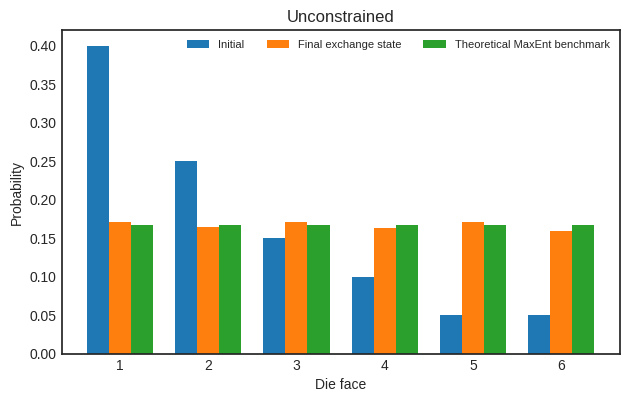

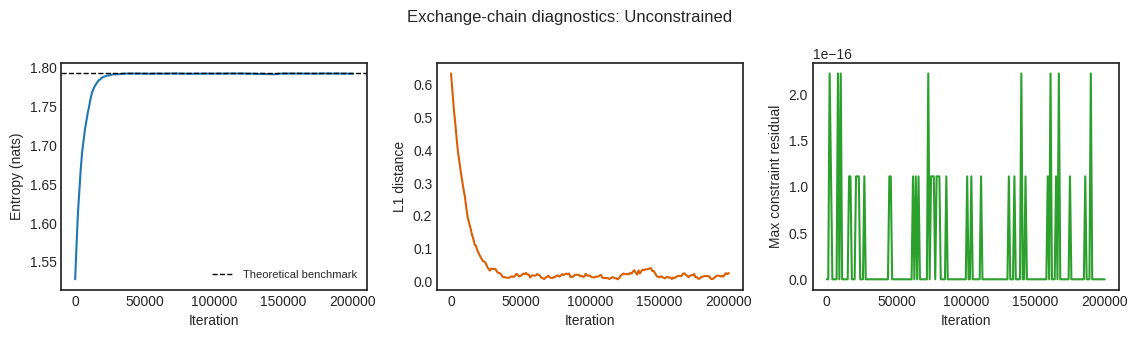

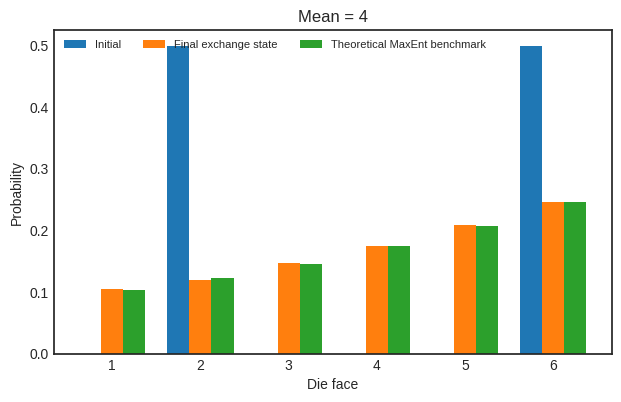

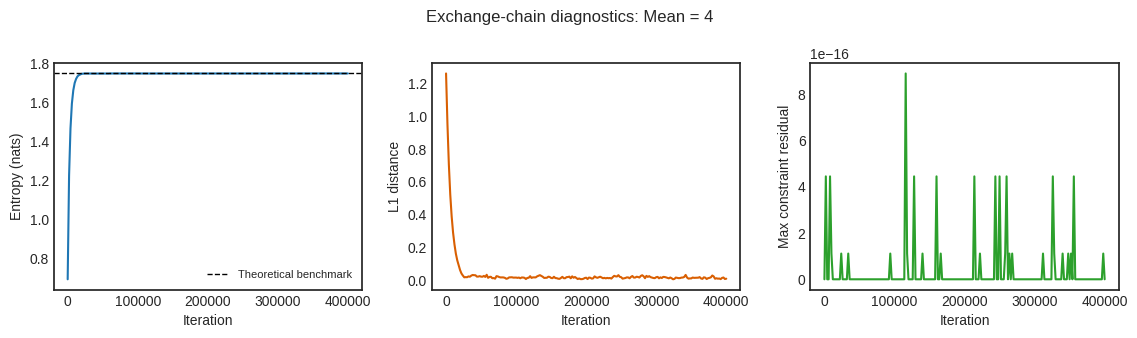

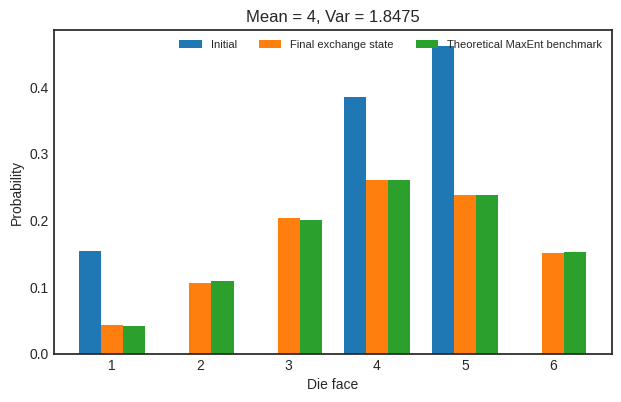

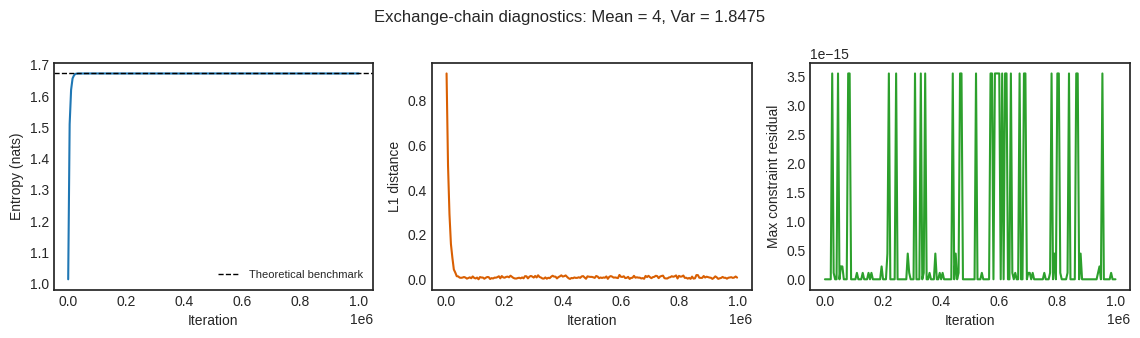

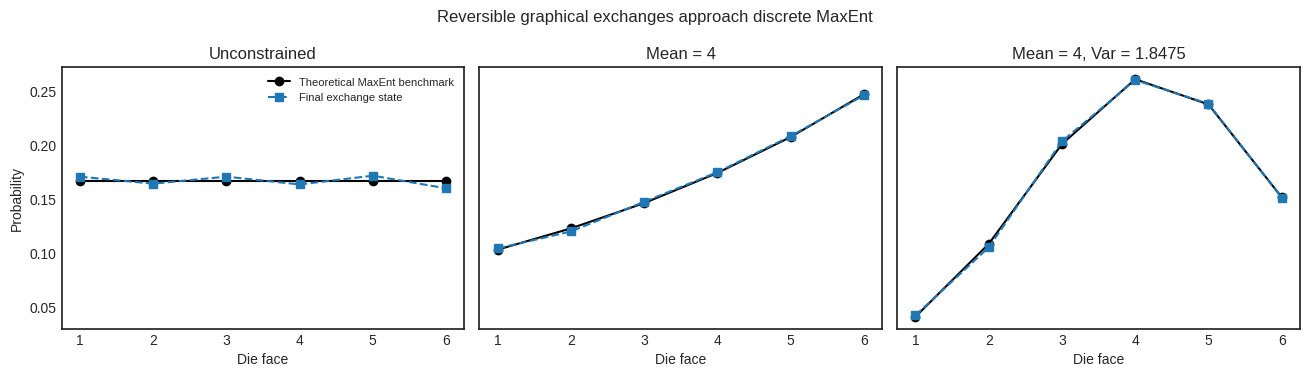

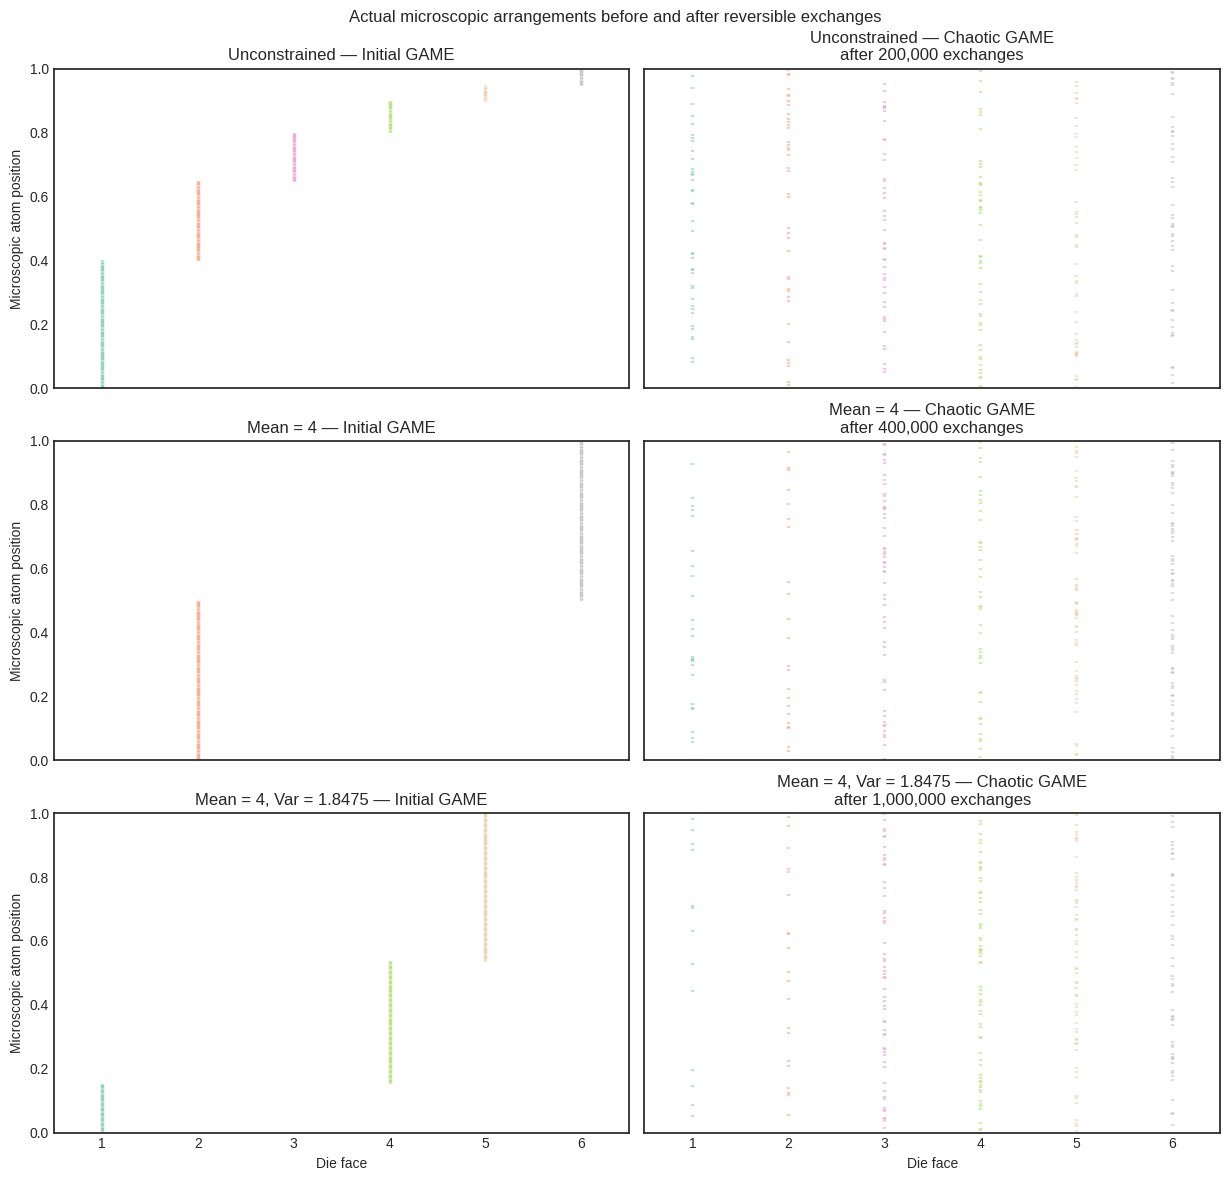

In [11]:
output_dir = Path(SETTINGS["output_dir"])
if not output_dir.is_absolute():
    output_dir = REPO_ROOT / output_dir


def save_figure(fig, stem, *, pdf=False):
    # Publication figures use a clean white field without underlying grids.
    for axis in fig.axes:
        axis.grid(False)
    if SETTINGS["write_outputs"]:
        output_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_dir / f"{stem}.png", dpi=220, bbox_inches="tight")
        if pdf:
            fig.savefig(output_dir / f"{stem}.pdf", bbox_inches="tight")


for experiment in study.values():
    key = experiment["key"]
    D = experiment["config"]["D"]
    positions = np.arange(6)
    width = 0.25
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    ax.bar(positions - width, experiment["initial_counts"] / D, width, label="Initial")
    ax.bar(
        positions,
        experiment["chain"].final_counts / D,
        width,
        label="Final exchange state",
    )
    ax.bar(
        positions + width,
        experiment["benchmark"],
        width,
        label="Theoretical MaxEnt benchmark",
    )
    ax.set(xticks=positions, xticklabels=OUTCOMES, xlabel="Die face", ylabel="Probability")
    ax.set_title(experiment["name"])
    ax.legend(frameon=False, ncol=3, fontsize=8)
    save_figure(fig, f"{key}_probabilities")
    plt.show()
    plt.close(fig)

    trace = experiment["trace"]
    fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4))
    axes[0].plot(trace["iteration"], trace["entropy"], color="#1f77b4")
    axes[0].axhline(
        experiment["final_diagnostic"]["maxent_entropy"],
        color="black",
        linestyle="--",
        linewidth=1,
        label="Theoretical benchmark",
    )
    axes[0].set(ylabel="Entropy (nats)", xlabel="Iteration")
    axes[0].legend(frameon=False, fontsize=8)
    axes[1].plot(trace["iteration"], trace["L1"], color="#d95f02")
    axes[1].set(ylabel="L1 distance", xlabel="Iteration")
    axes[2].plot(trace["iteration"], trace["max_constraint_residual"], color="#2ca02c")
    axes[2].set(ylabel="Max constraint residual", xlabel="Iteration")
    fig.suptitle(f"Exchange-chain diagnostics: {experiment['name']}")
    fig.tight_layout()
    save_figure(fig, f"{key}_convergence")
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.8), sharey=True)
for ax, experiment in zip(axes, study.values()):
    D = experiment["config"]["D"]
    ax.plot(
        OUTCOMES,
        experiment["benchmark"],
        "o-",
        color="black",
        label="Theoretical MaxEnt benchmark",
    )
    ax.plot(
        OUTCOMES,
        experiment["chain"].final_counts / D,
        "s--",
        color="#1f77b4",
        label="Final exchange state",
    )
    ax.set(title=experiment["name"], xlabel="Die face", xticks=OUTCOMES)
axes[0].set_ylabel("Probability")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Reversible graphical exchanges approach discrete MaxEnt")
fig.tight_layout()
save_figure(fig, "graphical_maxent_die_comparison", pdf=True)
plt.show()
plt.close(fig)


def draw_atom_segments(axis, atoms, outcomes, title):
    D = len(atoms)
    lower = np.arange(D, dtype=float) / D
    upper = (np.arange(D, dtype=float) + 0.82) / D
    colors = plt.cm.Set2(np.linspace(0.05, 0.95, len(outcomes)))
    for color, outcome in zip(colors, outcomes):
        atom_positions = np.flatnonzero(atoms == outcome)
        axis.vlines(
            np.full(len(atom_positions), outcome),
            lower[atom_positions],
            upper[atom_positions],
            color=color,
            linewidth=2.45,
            alpha=0.9,
        )
    axis.set(xlim=(0.5, 6.5), ylim=(0, 1), xticks=outcomes, title=title)
    axis.grid(False)


fig, axes = plt.subplots(3, 2, figsize=(12.4, 12.0), sharex=True, sharey=True)
for row, experiment in enumerate(study.values()):
    chain = experiment["chain"]
    draw_atom_segments(
        axes[row, 0],
        chain.initial_atoms,
        experiment["constraints"].outcomes,
        f"{experiment['name']} — Initial GAME",
    )
    draw_atom_segments(
        axes[row, 1],
        chain.final_atoms,
        experiment["constraints"].outcomes,
        f"{experiment['name']} — Chaotic GAME\nafter {chain.proposals:,} exchanges",
    )
    axes[row, 0].set_ylabel("Microscopic atom position")
for axis in axes[-1, :]:
    axis.set_xlabel("Die face")
fig.suptitle("Actual microscopic arrangements before and after reversible exchanges")
fig.tight_layout()
save_figure(fig, "die_game_segments_initial_vs_chaotic", pdf=True)
plt.show()
plt.close(fig)


In [12]:
if SETTINGS["write_outputs"]:
    output_dir.mkdir(parents=True, exist_ok=True)
    summary.to_csv(output_dir / "summary.csv", index=False, float_format="%.17g")
    final_distributions.to_csv(
        output_dir / "final_distributions.csv", index=False, float_format="%.17g"
    )
    block_diagnostics.to_csv(
        output_dir / "block_size_diagnostics.csv", index=False, float_format="%.17g"
    )
    for experiment in study.values():
        experiment["trace"].to_csv(
            output_dir / f"{experiment['key']}_checkpoints.csv",
            index=False,
            float_format="%.17g",
        )

    configuration = {
        "settings": SETTINGS,
        "finite_population": SETTINGS["finite_population"],
        "atom_selection": "ordered distinct atoms, multiplicity-weighted without replacement",
        "replacement": "uniform ordered pattern within exact constraint signature",
        "self_loops_retained": True,
        "block_weights": {
            "unconstrained": {1: 1.0},
            "mean": {2: 1.0},
            "two_moment": TWO_MOMENT_WEIGHTS,
        },
        "constraints": {
            key: {
                "features": value.features.tolist(),
                "targets": value.targets.tolist(),
            }
            for key, value in CONSTRAINTS.items()
        },
        "initial_counts": {
            experiment["key"]: experiment["initial_counts"].tolist()
            for experiment in study.values()
        },
        "theoretical_maxent": {
            key: value.tolist() for key, value in BENCHMARKS.items()
        },
    }
    with (output_dir / "configuration.json").open("w", encoding="utf-8") as stream:
        json.dump(configuration, stream, indent=2)

results = {
    "summary": summary,
    "final_distributions": final_distributions,
    "block_diagnostics": block_diagnostics,
    "study": study,
    "replay_pairs": [experiment["replay_pair"] for experiment in study.values()],
    "old_variance": old_variance,
    "d10000_infeasible": d10000_infeasible,
}
print(f"Artifacts written: {SETTINGS['write_outputs']}")
if SETTINGS["write_outputs"]:
    print(f"Output directory: {output_dir}")


Artifacts written: True
Output directory: /home/bardia/projects/graphical-sampling/simulations/results/graphical_maxent_die


# Continuese Case

In [13]:
# ============================================================
# CONTINUOUS GRAPHICAL MAXIMUM ENTROPY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import root
from scipy.special import logsumexp

from graphical_sampling.maxent import (
    MomentConstraints,
    ReplacementKernel,
    run_chain,
)


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

continuous_settings = globals().get("SETTINGS", {}).get(
    "continuous",
    {
        "D": 6_000,
        "iterations": 150_000,
        "burn_in": 50_000,
        "checkpoint_every": 500,
        "replicates": 8,
        "seed": 20_260_925,
    },
)

SEED = int(continuous_settings["seed"])
rng = np.random.default_rng(SEED)


# ------------------------------------------------------------
# Example constraints
# ------------------------------------------------------------

MU_MEAN_ONLY = 2.0

MU_MEAN_VAR = 5.0
VAR_MEAN_VAR = 4.0


# ------------------------------------------------------------
# Support and discretization
# ------------------------------------------------------------

XMIN = 0.0
XMAX = 10.0

K = 100

edges = np.linspace(XMIN, XMAX, K + 1)
assert len(edges) == K + 1
assert np.allclose(np.diff(edges), 0.1, rtol=0.0, atol=1e-14)

left = edges[:-1]
right = edges[1:]
width = right - left

centers = (left + right) / 2.0


# Exact first and second moments of a UNIFORM density
# within each individual interval.
#
# If interval j contains mass q_j and the density is constant
# inside the interval:
#
#     E[X | bin j]   = m1[j]
#     E[X^2 | bin j] = m2[j]
# ------------------------------------------------------------

m1 = (left + right) / 2.0

m2 = (
    left**2
    + left * right
    + right**2
) / 3.0


# ------------------------------------------------------------
# Microscopic atom-exchange settings
# ------------------------------------------------------------

N_ITER = int(continuous_settings["iterations"])
CHECKPOINT = int(continuous_settings["checkpoint_every"])
BURNIN = int(continuous_settings["burn_in"])
N_REPLICATES = int(continuous_settings["replicates"])
D_EFF = int(continuous_settings["D"])

assert D_EFF % 240 == 0
assert N_REPLICATES >= 2


print("K =", K)
print("Bin width =", width[0])
print("Microscopic atoms =", D_EFF)
print("Independent endpoint replicates =", N_REPLICATES)

K = 100
Bin width = 0.1
Microscopic atoms = 6000
Independent endpoint replicates = 8


In [14]:
# ============================================================
# MATHEMATICAL UTILITIES
# ============================================================


def continuous_cdf_curve(q, points_per_interval=15):
    """
    Continuous piecewise-linear CDF implied by piecewise-constant
    density on each interval.

    q[j] = probability mass in interval j.
    """

    xs = []
    Fs = []

    cumulative = 0.0

    for j, qj in enumerate(q):

        a = edges[j]
        b = edges[j + 1]

        density = qj / (b - a)

        x_local = np.linspace(
            a,
            b,
            points_per_interval,
            endpoint=False,
        )

        F_local = cumulative + density * (x_local - a)

        xs.extend(x_local)
        Fs.extend(F_local)

        cumulative += qj

    xs.append(edges[-1])
    Fs.append(1.0)

    return np.asarray(xs), np.asarray(Fs)


def density_curve(q):
    """
    Piecewise-constant density values.
    """
    return q / width


def entropy_density(q):
    """
    Differential entropy of the piecewise-constant density:

        h(f) = - integral f log f

    which becomes

        -sum q_j log(q_j / width_j)
    """

    q = np.asarray(q)

    positive = q > 0

    return -np.sum(
        q[positive]
        * np.log(q[positive] / width[positive])
    )


def distribution_moments(q):
    """
    Exact moments under the piecewise-constant approximation.
    """

    mean = np.sum(q * m1)

    second = np.sum(q * m2)

    variance = second - mean**2

    return mean, variance


def maxent_from_reference(reference_mass, features, targets):
    """
    Solve the finite-resolution maximum-entropy / exponential-family
    problem.

    reference_mass:
        base interval masses. For ordinary continuous entropy,
        use interval widths.

    features:
        array shape (number_constraints, K)

    targets:
        desired expectations.
    """

    reference_mass = np.asarray(reference_mass, dtype=float)

    features = np.atleast_2d(features)

    targets = np.asarray(targets, dtype=float)

    log_reference = np.log(reference_mass)

    def probabilities(lam):

        z = log_reference + lam @ features

        z -= logsumexp(z)

        return np.exp(z)

    def equations(lam):

        q = probabilities(lam)

        return features @ q - targets

    solution = root(
        equations,
        np.zeros(features.shape[0]),
    )

    if not solution.success:
        raise RuntimeError(
            f"MaxEnt solver failed: {solution.message}"
        )

    q = probabilities(solution.x)

    return q, solution.x


def smooth_feasible_distribution(
    base_shape,
    features,
    targets,
):
    """
    Construct a smooth positive NON-MaxEnt feasible distribution.

    We start from a deliberately nonuniform smooth base density and
    exponentially tilt it only enough to satisfy the constraints.
    """

    base_mass = width * np.asarray(base_shape)

    q, lam = maxent_from_reference(
        base_mass,
        features,
        targets,
    )

    return q, lam

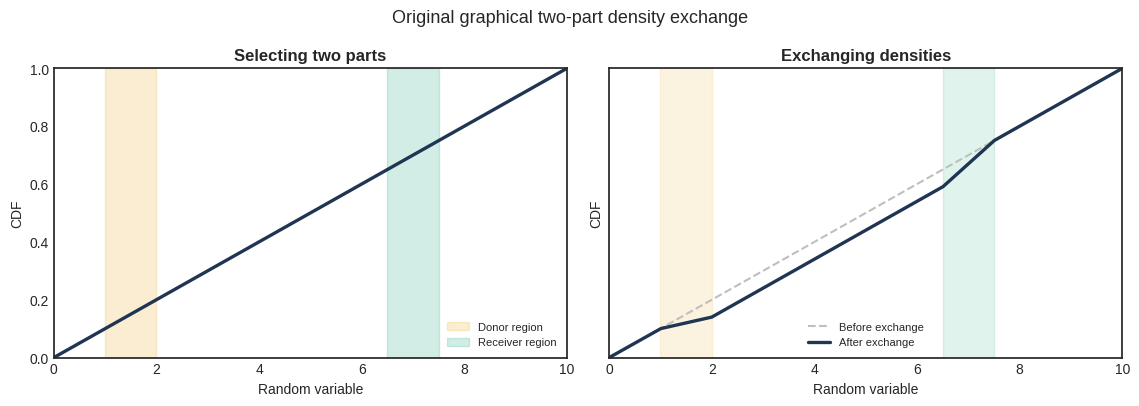

In [15]:
# ============================================================
# ORIGINAL TWO-PART GRAPHICAL IDEA
# ============================================================

# Start from Uniform[0,10], exactly like the straight-line CDF
# in your original figure.

q_uniform = width / (XMAX - XMIN)


# Select two wide, separated regions. Each region has ten bins.
donor_bins = np.arange(10, 20)
receiver_bins = np.arange(65, 75)

delta_per_bin = 0.006


q_two_part = q_uniform.copy()

q_two_part[donor_bins] -= delta_per_bin
q_two_part[receiver_bins] += delta_per_bin


assert np.all(q_two_part >= 0)
assert np.isclose(q_two_part.sum(), 1.0)


# Continuous CDFs
x_before, F_before = continuous_cdf_curve(q_uniform)
x_after, F_after = continuous_cdf_curve(q_two_part)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(11.5, 4.1),
    sharex=True,
    sharey=True,
)


# ------------------------------------------------------------
# BEFORE
# ------------------------------------------------------------

axes[0].plot(
    x_before,
    F_before,
    color="#1f3552",
    linewidth=2.4,
)

axes[0].axvspan(
    edges[donor_bins[0]],
    edges[donor_bins[-1] + 1],
    color="#e69f00",
    alpha=0.18,
    label="Donor region",
)

axes[0].axvspan(
    edges[receiver_bins[0]],
    edges[receiver_bins[-1] + 1],
    color="#009e73",
    alpha=0.18,
    label="Receiver region",
)

axes[0].legend(frameon=False, fontsize=8)

axes[0].set_title(
    "Selecting two parts",
    fontweight="bold",
)


# ------------------------------------------------------------
# AFTER
# ------------------------------------------------------------

axes[1].plot(
    x_before,
    F_before,
    color="0.75",
    linewidth=1.5,
    linestyle="--",
    label="Before exchange",
)

axes[1].plot(
    x_after,
    F_after,
    color="#1f3552",
    linewidth=2.4,
    label="After exchange",
)

axes[1].axvspan(
    edges[donor_bins[0]],
    edges[donor_bins[-1] + 1],
    color="#e69f00",
    alpha=0.12,
)

axes[1].axvspan(
    edges[receiver_bins[0]],
    edges[receiver_bins[-1] + 1],
    color="#009e73",
    alpha=0.12,
)

axes[1].set_title(
    "Exchanging densities",
    fontweight="bold",
)

axes[1].legend(
    frameon=False,
    fontsize=8,
)


for ax in axes:

    ax.set(
        xlim=(XMIN, XMAX),
        ylim=(0, 1),
        xlabel="Random variable",
        ylabel="CDF",
    )

    ax.grid(False)


fig.suptitle(
    "Original graphical two-part density exchange",
    fontsize=13,
)

fig.tight_layout()

plt.show()

In [ ]:
# ============================================================
# PHASE 1: START FROM UNIFORM AND APPROACH THE TARGET MEAN
# BY GRAPHICAL SLOPE / PROBABILITY-MASS EXCHANGES
# ============================================================

TARGET_MEAN = 2.0

# Change in density (slope of the CDF)
NU = 0.02

# Equal interval width
h = float(width[0])

# Corresponding probability mass moved in one exchange
BASE_DELTA = NU * h

MAX_ITER = 100_000
TOL = 1e-12

rng_approach = np.random.default_rng(SEED + 100)

# Start EXACTLY from Uniform[0,10]
q_approach = q_uniform.copy()


def mean_from_q(q):
    return float(np.sum(q * m1))


mean_history = [mean_from_q(q_approach)]
accepted_history = [0]

accepted = 0
rejected = 0


for iteration in range(1, MAX_ITER + 1):

    current_mean = mean_from_q(q_approach)
    current_error = abs(current_mean - TARGET_MEAN)

    if current_error <= TOL:
        break

    # Randomly select two different h-strips
    donor, receiver = rng_approach.choice(
        K,
        size=2,
        replace=False,
    )

    # Cannot remove probability from an empty interval
    if q_approach[donor] <= 0:
        rejected += 1
        continue

    delta = min(BASE_DELTA, q_approach[donor])

    proposed = q_approach.copy()

    proposed[donor] -= delta
    proposed[receiver] += delta

    proposed_mean = mean_from_q(proposed)
    proposed_error = abs(proposed_mean - TARGET_MEAN)

    # --------------------------------------------
    # YOUR ACCEPTANCE RULE
    # --------------------------------------------
    if proposed_error < current_error:

        q_approach = proposed
        accepted += 1

        mean_history.append(proposed_mean)
        accepted_history.append(accepted)

    else:

        # Check whether this was a correct-direction move
        # that merely jumped across the target.
        direction_effect = m1[receiver] - m1[donor]

        if direction_effect != 0:

            delta_to_target = (
                TARGET_MEAN - current_mean
            ) / direction_effect

            if 0 < delta_to_target <= delta:

                proposed = q_approach.copy()

                proposed[donor] -= delta_to_target
                proposed[receiver] += delta_to_target

                q_approach = proposed
                accepted += 1

                mean_history.append(
                    mean_from_q(q_approach)
                )
                accepted_history.append(accepted)

                break

        rejected += 1


print("Initial mean =", mean_from_q(q_uniform))
print("Final mean   =", mean_from_q(q_approach))
print("Accepted exchanges =", accepted)
print("Rejected proposals =", rejected)
print("Total probability =", q_approach.sum())


# ------------------------------------------------------------
# Plot movement toward the target
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11.5, 4.1),
)


axes[0].plot(
    accepted_history,
    mean_history,
    linewidth=2,
)

axes[0].axhline(
    TARGET_MEAN,
    linestyle="--",
    color="black",
)

axes[0].set(
    xlabel="Accepted exchanges",
    ylabel="Mean",
    title="Approaching the target mean",
)


x_uniform, F_uniform = continuous_cdf_curve(q_uniform)
x_approach, F_approach = continuous_cdf_curve(q_approach)

axes[1].plot(
    x_uniform,
    F_uniform,
    "--",
    label="Initial Uniform[0,10]",
)

axes[1].plot(
    x_approach,
    F_approach,
    linewidth=2,
    label="After accepted exchanges",
)

axes[1].set(
    xlabel="x",
    ylabel="CDF",
    title="Graphical deformation of the CDF",
)

axes[1].legend(frameon=False)

for ax in axes:
    ax.grid(False)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# PHASE 2: GRAPHICAL EXCHANGES THAT PRESERVE THE TARGET MEAN
# ============================================================

q_feasible = q_approach.copy()

N_MOVES = 5000
BASE_DELTA = 0.002

rng_preserve = np.random.default_rng(SEED + 200)

accepted = 0
mean_preserved_history = [mean_from_q(q_feasible)]

for iteration in range(N_MOVES):

    # Pick four different h-strips
    i, j, k, l = rng_preserve.choice(
        K,
        size=4,
        replace=False,
    )

    # Mean effect per unit probability mass
    a = m1[j] - m1[i]      # effect of i -> j
    b = m1[l] - m1[k]      # effect of k -> l

    # We need opposite directions:
    # one transfer increases the mean, the other decreases it
    if a * b >= 0:
        continue

    if q_feasible[i] <= 0 or q_feasible[k] <= 0:
        continue

    # From
    # delta1*a + delta2*b = 0
    # we obtain:
    ratio = -a / b

    if ratio <= 0:
        continue

    # delta2 = ratio * delta1
    # Respect available mass in BOTH donor strips
    delta1 = min(
        BASE_DELTA,
        q_feasible[i],
        q_feasible[k] / ratio,
    )

    if delta1 <= 0:
        continue

    delta2 = ratio * delta1

    proposed = q_feasible.copy()

    # First graphical transfer: i -> j
    proposed[i] -= delta1
    proposed[j] += delta1

    # Second graphical transfer: k -> l
    proposed[k] -= delta2
    proposed[l] += delta2

    # Numerical safety
    if np.any(proposed < -1e-14):
        continue

    proposed[proposed < 0] = 0.0

    q_feasible = proposed
    accepted += 1

    mean_preserved_history.append(
        mean_from_q(q_feasible)
    )


print("Accepted preserving exchanges =", accepted)
print("Total probability =", q_feasible.sum())
print("Mean before Phase 2 =", mean_from_q(q_approach))
print("Mean after Phase 2  =", mean_from_q(q_feasible))
print(
    "Maximum mean deviation =",
    np.max(
        np.abs(
            np.array(mean_preserved_history)
            - TARGET_MEAN
        )
    ),
)


# ------------------------------------------------------------
# Visualize the result
# ------------------------------------------------------------

x_before, F_before = continuous_cdf_curve(q_approach)
x_after, F_after = continuous_cdf_curve(q_feasible)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11.5, 4.1),
)

axes[0].plot(
    mean_preserved_history,
    linewidth=1.5,
)

axes[0].axhline(
    TARGET_MEAN,
    linestyle="--",
    color="black",
)

axes[0].set(
    xlabel="Accepted exchanges",
    ylabel="Mean",
    title="Mean remains fixed",
)


axes[1].plot(
    x_before,
    F_before,
    "--",
    label="Start of Phase 2",
)

axes[1].plot(
    x_after,
    F_after,
    linewidth=2,
    label="After graphical exchanges",
)

axes[1].set(
    xlabel="x",
    ylabel="CDF",
    title="Different distribution, same mean",
)

axes[1].legend(frameon=False)

for ax in axes:
    ax.grid(False)

plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# EXACT MICROSCOPIC CONSTRAINTS, FEASIBLE STARTS,
# AND INDEPENDENT THEORETICAL MAXENT BENCHMARKS
# ============================================================


# On the equal 0.1-wide grid, exact interval moments are integer-scaled:
#   20 E[X | bin j]   = 2j + 1
#  300 E[X² | bin j] = 3j² + 3j + 1.
# These integer signatures make every microscopic exchange exact.
bin_ids = np.arange(K, dtype=int)
mean_signature = 2 * bin_ids + 1
second_signature = 3 * bin_ids**2 + 3 * bin_ids + 1


# ------------------------------------------------------------
# CASE 1: MEAN ONLY
# ------------------------------------------------------------

features_mean = np.vstack([m1])

targets_mean = np.array([
    MU_MEAN_ONLY,
])


# True finite-resolution MaxEnt benchmark:
# reference measure = Lebesgue measure -> interval widths
qstar_mean, lambda_mean = maxent_from_reference(
    width,
    features_mean,
    targets_mean,
)

continuous_constraints_mean = MomentConstraints.from_moments(
    bin_ids,
    [mean_signature],
    [20.0 * MU_MEAN_ONLY],
)
continuous_kernel_mean = ReplacementKernel(
    continuous_constraints_mean,
    {2: 1.0},
)

# Begin from the exact microscopic Uniform[0,10], whose mean is 5.
# Move one atom per proposal until the exact mean-2 signature is reached.
# Acceptance uses only strict reduction of the integer signature error.
assert D_EFF % K == 0
initial_counts_mean = np.full(K, D_EFF // K, dtype=np.int64)
target_signature_mean = int(round(D_EFF * 20.0 * MU_MEAN_ONLY))
current_signature = int(initial_counts_mean @ mean_signature)
starting_signature_mean = current_signature
approach_history = [current_signature / (20.0 * D_EFF)]
accepted_approach = 0
rejected_approach = 0
MAX_APPROACH_ITER = 1_000_000
approach_acceptance_rule = "strict exact integer signature-error reduction"
rng_mean_approach = np.random.default_rng(SEED + 300)

for _ in range(MAX_APPROACH_ITER):
    if current_signature == target_signature_mean:
        break

    occupied_bins = np.flatnonzero(initial_counts_mean > 0)
    donor = int(rng_mean_approach.choice(occupied_bins))
    receiver = int(rng_mean_approach.integers(K - 1))
    if receiver >= donor:
        receiver += 1

    signature_change = int(mean_signature[receiver] - mean_signature[donor])
    proposed_signature = current_signature + signature_change
    current_error = abs(current_signature - target_signature_mean)
    proposed_error = abs(proposed_signature - target_signature_mean)

    if proposed_error < current_error:
        initial_counts_mean[donor] -= 1
        initial_counts_mean[receiver] += 1
        current_signature = proposed_signature
        accepted_approach += 1
        approach_history.append(current_signature / (20.0 * D_EFF))
    else:
        rejected_approach += 1

if current_signature != target_signature_mean:
    raise RuntimeError(
        "Mean-only approach phase did not reach the exact target "
        f"within {MAX_APPROACH_ITER:,} proposals"
    )

print("Starting mean =", starting_signature_mean / (20.0 * D_EFF))
print("Reached mean  =", current_signature / (20.0 * D_EFF))
print("Accepted approach moves =", accepted_approach)
print("Rejected approach moves =", rejected_approach)

continuous_constraints_mean.validate_counts(initial_counts_mean)
q0_mean = initial_counts_mean.astype(float) / D_EFF
q0_mean.setflags(write=False)


# ------------------------------------------------------------
# CASE 2: MEAN + VARIANCE
# ------------------------------------------------------------

SECOND_TARGET = (
    MU_MEAN_VAR**2
    + VAR_MEAN_VAR
)

features_mv = np.vstack([
    m1,
    m2,
])

targets_mv = np.array([
    MU_MEAN_VAR,
    SECOND_TARGET,
])


qstar_mv, lambda_mv = maxent_from_reference(
    width,
    features_mv,
    targets_mv,
)

continuous_constraints_mv = MomentConstraints.from_moments(
    bin_ids,
    [mean_signature, second_signature],
    [20.0 * MU_MEAN_VAR, 300.0 * SECOND_TARGET],
)
continuous_kernel_mv = ReplacementKernel(
    continuous_constraints_mv,
    {3: 1.0},
)

# A symmetric four-bin microscopic start with exact mean 5 and variance 4.
# Each count is an integer; no continuous projection or entropy optimizer is used.
initial_counts_mv = np.zeros(K, dtype=np.int64)
initial_counts_mv[[29, 70]] = D_EFF * 59 // 240
initial_counts_mv[[30, 69]] = D_EFF * 61 // 240
continuous_constraints_mv.validate_counts(initial_counts_mv)
q0_mv = initial_counts_mv.astype(float) / D_EFF
q0_mv.setflags(write=False)


# ------------------------------------------------------------
# CHECKS
# ------------------------------------------------------------

mean0, var0 = distribution_moments(q0_mean)
np.testing.assert_allclose(
    mean0,
    MU_MEAN_ONLY,
    rtol=0.0,
    atol=1e-12,
)
np.testing.assert_allclose(
    distribution_moments(q0_mv),
    (MU_MEAN_VAR, VAR_MEAN_VAR),
    rtol=0.0,
    atol=1e-12,
)

print("MEAN-ONLY")
print("Initial moments :", distribution_moments(q0_mean))
print("MaxEnt moments  :", distribution_moments(qstar_mean))
print("Initial entropy :", entropy_density(q0_mean))
print("MaxEnt entropy  :", entropy_density(qstar_mean))

print()

print("MEAN + VARIANCE")
print("Initial moments :", distribution_moments(q0_mv))
print("MaxEnt moments  :", distribution_moments(qstar_mv))
print("Initial entropy :", entropy_density(q0_mv))
print("MaxEnt entropy  :", entropy_density(qstar_mv))

Starting mean = 5.0
Reached mean  = 2.0
Accepted approach moves = 5927
Rejected approach moves = 8003


MEAN-ONLY
Initial moments : (np.float64(2.0), np.float64(2.0280266666666673))
MaxEnt moments  : (np.float64(2.000000000000068), np.float64(3.501529314794091))
Initial entropy : 1.5895461324561442
MaxEnt entropy  : 1.685609297614381

MEAN + VARIANCE
Initial moments : (np.float64(5.0), np.float64(4.0000000000000036))
MaxEnt moments  : (np.float64(4.999999999999982), np.float64(3.999999999999986))
Initial entropy : -0.9164296271937997
MaxEnt entropy  : 2.0967210452952956


In [19]:
# ============================================================
# EXACT MICROSCOPIC ATOM-EXCHANGE DIAGNOSTICS
# ============================================================


def continuous_chain_trace(chain, benchmark, constraints):
    """Compute diagnostics after sampling; none enter the transition rule."""
    atom_count = int(chain.final_counts.sum())
    probabilities = chain.checkpoint_counts.astype(float) / atom_count
    expected = constraints.integer_rhs(atom_count)
    actual = chain.checkpoint_counts @ constraints.constraint_matrix.T
    max_constraint_error = int(np.max(np.abs(actual - expected)))
    records = []
    for iteration, q in zip(chain.checkpoint_iterations, probabilities):
        mean, variance = distribution_moments(q)
        records.append(
            {
                "iteration": int(iteration),
                "entropy": entropy_density(q),
                "L1": float(np.sum(np.abs(q - benchmark))),
                "L2": float(np.sqrt(np.sum((q - benchmark) ** 2))),
                "CDF sup": float(np.max(np.abs(np.cumsum(q - benchmark)))),
                "mean": float(mean),
                "variance": float(variance),
                "constraint_residual": max_constraint_error,
            }
        )
    return pd.DataFrame(records), max_constraint_error


def run_microscopic_continuous_chain(
    initial_counts, constraints, kernel, benchmark, seed
):
    """Run unconditional signature-preserving atom exchanges."""
    chain = run_chain(
        initial_counts,
        constraints,
        kernel,
        iterations=N_ITER,
        seed=int(seed),
        checkpoint_every=CHECKPOINT,
        burn_in=BURNIN,
        track_atoms=False,
    )
    trace, max_constraint_error = continuous_chain_trace(
        chain, benchmark, constraints
    )
    final = chain.final_counts.astype(float) / D_EFF
    post_burn = chain.checkpoint_iterations >= BURNIN
    checkpoint_mean = (
        chain.checkpoint_counts[post_burn].mean(axis=0) / D_EFF
        if np.any(post_burn)
        else final.copy()
    )
    return {
        "chain": chain,
        "final": final,
        "checkpoint_mean": checkpoint_mean,
        "trace": trace,
        "proposal_acceptance": 1.0,
        "change_rate": chain.change_rate,
        "max_constraint_error": float(max_constraint_error),
    }


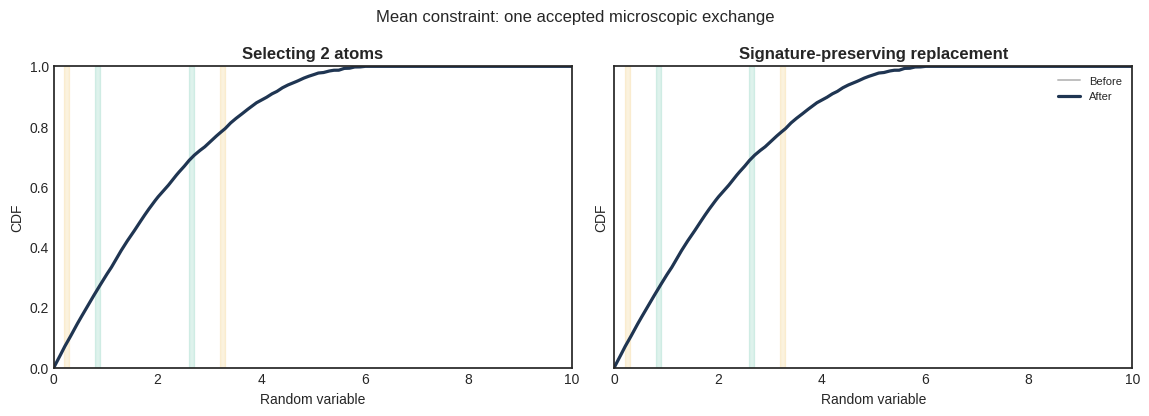

Source bin labels: (32, 2)
Replacement bin labels: (8, 26)
Exact signature change: [0 0]


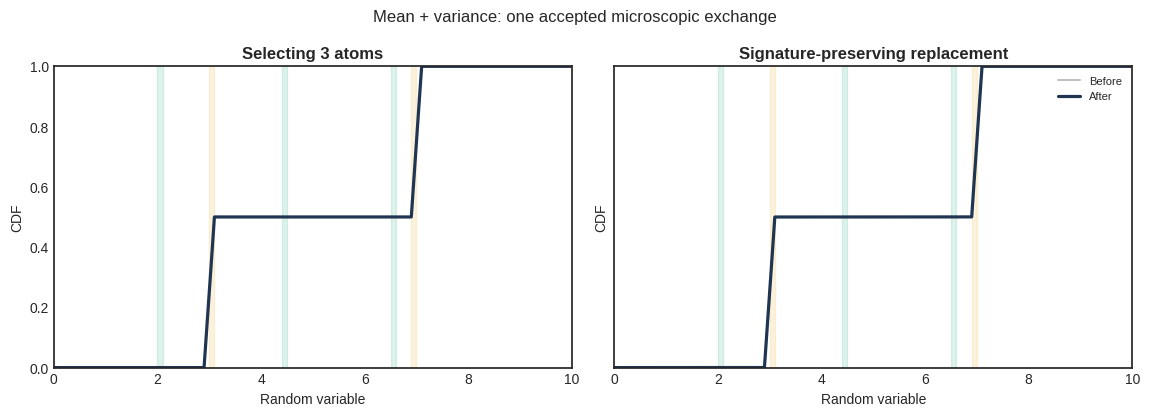

Source bin labels: (30, 69, 30)
Replacement bin labels: (65, 20, 44)
Exact signature change: [0 0 0]


In [20]:
# ============================================================
# VISUALIZE ONE ACTUAL ACCEPTED MICROSCOPIC EXCHANGE
# ============================================================


def find_changed_microscopic_exchange(initial_counts, kernel, seed, max_attempts=10_000):
    """Find a changed proposal for illustration; production chains retain self-loops."""
    counts = np.asarray(initial_counts, dtype=np.int64).copy()
    before = counts.copy()
    rng = np.random.default_rng(seed)
    for _ in range(max_attempts):
        step_result = kernel.step_inplace(counts, rng)
        if step_result.changed:
            return before, counts.copy(), step_result
    raise RuntimeError("No changed microscopic proposal found for the illustration")


def plot_microscopic_exchange(initial_counts, constraints, kernel, title, seed):
    before_counts, after_counts, step_result = find_changed_microscopic_exchange(
        initial_counts, kernel, seed
    )
    np.testing.assert_array_equal(
        constraints.constraint_matrix @ before_counts,
        constraints.constraint_matrix @ after_counts,
    )
    q_before = before_counts / before_counts.sum()
    q_after = after_counts / after_counts.sum()
    x_before, F_before = continuous_cdf_curve(q_before)
    x_after, F_after = continuous_cdf_curve(q_after)
    delta = after_counts - before_counts
    changed_bins = np.flatnonzero(delta)

    fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.2), sharex=True, sharey=True)
    axes[0].plot(x_before, F_before, color="#1f3552", linewidth=2.3)
    axes[0].set_title(f"Selecting {step_result.block_size} atoms", fontweight="bold")
    axes[1].plot(x_before, F_before, color="0.75", linewidth=1.4, label="Before")
    axes[1].plot(x_after, F_after, color="#1f3552", linewidth=2.3, label="After")
    axes[1].set_title("Signature-preserving replacement", fontweight="bold")
    for bin_index in changed_bins:
        color = "#009e73" if delta[bin_index] > 0 else "#e69f00"
        for axis in axes:
            axis.axvspan(edges[bin_index], edges[bin_index + 1], color=color, alpha=0.13)
    for axis in axes:
        axis.set(xlim=(XMIN, XMAX), ylim=(0, 1), xlabel="Random variable", ylabel="CDF")
        axis.grid(False)
    axes[1].legend(frameon=False, fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    print("Source bin labels:", step_result.source_labels)
    print("Replacement bin labels:", step_result.target_labels)
    print("Exact signature change:", constraints.constraint_matrix @ (after_counts - before_counts))
    return after_counts, step_result


mean_exchange_demo = plot_microscopic_exchange(
    initial_counts_mean, continuous_constraints_mean, continuous_kernel_mean,
    "Mean constraint: one accepted microscopic exchange", SEED + 10,
)
mv_exchange_demo = plot_microscopic_exchange(
    initial_counts_mv, continuous_constraints_mv, continuous_kernel_mv,
    "Mean + variance: one accepted microscopic exchange", SEED + 11,
)


In [21]:
# ============================================================
# WHY MAXENT IS A CONSEQUENCE, NOT AN ACCEPTANCE RULE
# ============================================================

# Source atoms are sampled according to their current multiplicities.
# Replacements are uniform over ordered patterns with the same exact
# integer moment signature. The source pattern is included, so self-loops
# remain. Forward and reverse microscopic proposal probabilities match,
# and every proposal is accepted. A count macrostate c inherits
# D! / product(c_j!) labeled realizations, whose logarithm is D times
# entropy to leading order.
continuous_reversibility = pd.DataFrame(
    [
        {"case": "Mean", "block size": 2, "proposal acceptance": 1.0,
         "entropy in transition": False, "self-loops retained": True},
        {"case": "Mean + variance", "block size": 3, "proposal acceptance": 1.0,
         "entropy in transition": False, "self-loops retained": True},
    ]
)
display(continuous_reversibility)


,case,block size,proposal acceptance,entropy in transition,self-loops retained
0,Mean,2,1.0,False,True
1,Mean + variance,3,1.0,False,True


In [22]:
# ============================================================
# RUN CONTINUOUS GRAPHICAL MAXENT
# ============================================================


result_mean = run_microscopic_continuous_chain(
    initial_counts_mean,
    continuous_constraints_mean,
    continuous_kernel_mean,
    qstar_mean,
    SEED + 1,
)

result_mv = run_microscopic_continuous_chain(
    initial_counts_mv,
    continuous_constraints_mv,
    continuous_kernel_mv,
    qstar_mv,
    SEED + 2,
)


def independent_endpoints(
    primary, initial_counts, constraints, kernel, benchmark, seed_offset
):
    runs = [primary]
    for replicate in range(1, N_REPLICATES):
        runs.append(
            run_microscopic_continuous_chain(
                initial_counts,
                constraints,
                kernel,
                benchmark,
                SEED + seed_offset + replicate,
            )
        )
    endpoints = np.stack([run["final"] for run in runs])
    endpoint_cdfs = np.stack(
        [continuous_cdf_curve(q)[1] for q in endpoints]
    )
    return runs, endpoints, endpoint_cdfs


mean_runs, mean_endpoints, mean_endpoint_cdfs = independent_endpoints(
    result_mean,
    initial_counts_mean,
    continuous_constraints_mean,
    continuous_kernel_mean,
    qstar_mean,
    100,
)
mv_runs, mv_endpoints, mv_endpoint_cdfs = independent_endpoints(
    result_mv,
    initial_counts_mv,
    continuous_constraints_mv,
    continuous_kernel_mv,
    qstar_mv,
    1_000,
)

q_gme_mean = result_mean["final"]
q_gme_mv = result_mv["final"]

mean_cdf_band = np.quantile(mean_endpoint_cdfs, [0.025, 0.975], axis=0)
mv_cdf_band = np.quantile(mv_endpoint_cdfs, [0.025, 0.975], axis=0)
x_cdf, Fstar_mean = continuous_cdf_curve(qstar_mean)
_, Fstar_mv = continuous_cdf_curve(qstar_mv)
_, Ffinal_mean = continuous_cdf_curve(q_gme_mean)
_, Ffinal_mv = continuous_cdf_curve(q_gme_mv)

continuous_results = {
    "mechanism": "microscopic signature-preserving atom exchanges",
    "entropy_used_in_transition": False,
    "replicates": N_REPLICATES,
    "uniform_reference_moments": distribution_moments(q_uniform),
    "mean": {
        "proposal_acceptance": 1.0,
        "change_rate": result_mean["change_rate"],
        "max_constraint_error": max(
            run["max_constraint_error"] for run in mean_runs
        ),
        "endpoint_cdfs": mean_endpoint_cdfs,
        "cdf_band_lower": mean_cdf_band[0],
        "cdf_band_upper": mean_cdf_band[1],
        "final_cdf_sup_error": float(np.max(np.abs(Ffinal_mean - Fstar_mean))),
        "final_L1_error": float(np.sum(np.abs(q_gme_mean - qstar_mean))),
    },
    "mean_variance": {
        "proposal_acceptance": 1.0,
        "change_rate": result_mv["change_rate"],
        "max_constraint_error": max(
            run["max_constraint_error"] for run in mv_runs
        ),
        "endpoint_cdfs": mv_endpoint_cdfs,
        "cdf_band_lower": mv_cdf_band[0],
        "cdf_band_upper": mv_cdf_band[1],
        "final_cdf_sup_error": float(np.max(np.abs(Ffinal_mv - Fstar_mv))),
        "final_L1_error": float(np.sum(np.abs(q_gme_mv - qstar_mv))),
    },
}
results["continuous"] = continuous_results


print("MEAN CONSTRAINT")
print("----------------")

print(
    "Initial:",
    distribution_moments(q0_mean),
)

print(
    "Final microscopic exchange state:",
    distribution_moments(q_gme_mean),
)

print(
    "MaxEnt:",
    distribution_moments(qstar_mean),
)

print(
    "Proposal acceptance / count-change rate:",
    result_mean["proposal_acceptance"],
    result_mean["change_rate"],
)

print(
    "L1 to MaxEnt:",
    continuous_results["mean"]["final_L1_error"],
)
print("CDF sup error:", continuous_results["mean"]["final_cdf_sup_error"])


print("\nMEAN + VARIANCE")
print("----------------")

print(
    "Initial:",
    distribution_moments(q0_mv),
)

print(
    "Final microscopic exchange state:",
    distribution_moments(q_gme_mv),
)

print(
    "MaxEnt:",
    distribution_moments(qstar_mv),
)

print(
    "Proposal acceptance / count-change rate:",
    result_mv["proposal_acceptance"],
    result_mv["change_rate"],
)

print(
    "L1 to MaxEnt:",
    continuous_results["mean_variance"]["final_L1_error"],
)
print(
    "CDF sup error:",
    continuous_results["mean_variance"]["final_cdf_sup_error"],
)

MEAN CONSTRAINT
----------------
Initial: (np.float64(2.0), np.float64(2.0280266666666673))
Final microscopic exchange state: (np.float64(2.0000000000000004), np.float64(3.5281433333333334))
MaxEnt: (np.float64(2.000000000000068), np.float64(3.501529314794091))
Proposal acceptance / count-change rate: 1.0 0.9094133333333333
L1 to MaxEnt: 0.09269359813172177
CDF sup error: 0.007646318657473339

MEAN + VARIANCE
----------------
Initial: (np.float64(5.0), np.float64(4.0000000000000036))
Final microscopic exchange state: (np.float64(5.0), np.float64(4.0000000000000036))
MaxEnt: (np.float64(4.999999999999982), np.float64(3.999999999999986))
Proposal acceptance / count-change rate: 1.0 0.31299333333333335
L1 to MaxEnt: 0.09867348938846926
CDF sup error: 0.006431390989407593


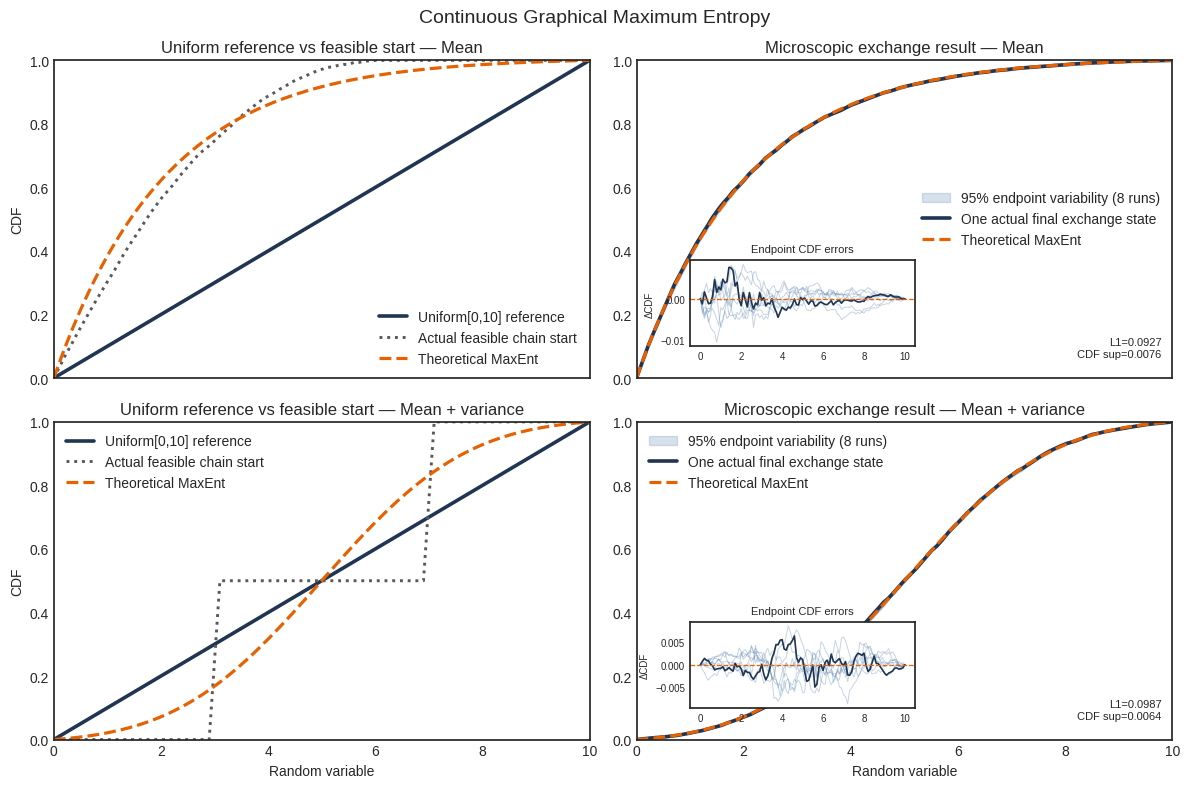

In [23]:
# ============================================================
# MAIN CONTINUOUS CDF FIGURE
# ============================================================


x_reference, F_reference = continuous_cdf_curve(
    q_uniform
)

x0_mean, F0_mean = continuous_cdf_curve(
    q0_mean
)

xg_mean, Fg_mean = continuous_cdf_curve(
    q_gme_mean
)

xs_mean, Fs_mean = continuous_cdf_curve(
    qstar_mean
)


x0_mv, F0_mv = continuous_cdf_curve(
    q0_mv
)

xg_mv, Fg_mv = continuous_cdf_curve(
    q_gme_mv
)

xs_mv, Fs_mv = continuous_cdf_curve(
    qstar_mv
)


fig, axes = plt.subplots(
    2,
    2,
    figsize=(12.0, 8.0),
    sharex=True,
)


# ============================================================
# MEAN — UNCONDITIONED REFERENCE AND FEASIBLE START
# ============================================================

axes[0, 0].plot(
    x_reference,
    F_reference,
    linewidth=2.6,
    color="#1f3552",
    label="Uniform[0,10] reference",
)

axes[0, 0].plot(
    x0_mean,
    F0_mean,
    ":",
    linewidth=2.1,
    color="0.35",
    label="Actual feasible chain start",
)

axes[0, 0].plot(
    xs_mean,
    Fs_mean,
    "--",
    linewidth=2.3,
    color="#e66101",
    label="Theoretical MaxEnt",
)

axes[0, 0].set_title(
    "Uniform reference vs feasible start — Mean"
)

axes[0, 0].legend(
    frameon=False
)


# ============================================================
# MEAN — AFTER EXCHANGES
# ============================================================

axes[0, 1].fill_between(
    xg_mean,
    mean_cdf_band[0],
    mean_cdf_band[1],
    color="#4c78a8",
    alpha=0.22,
    label=f"95% endpoint variability ({N_REPLICATES} runs)",
)

for endpoint_cdf in mean_endpoint_cdfs:
    axes[0, 1].plot(
        xg_mean, endpoint_cdf, color="#4c78a8", linewidth=0.8, alpha=0.25
    )

axes[0, 1].plot(
    xg_mean,
    Fg_mean,
    linewidth=2.6,
    color="#1f3552",
    label="One actual final exchange state",
)

axes[0, 1].plot(
    xs_mean,
    Fs_mean,
    "--",
    linewidth=2.3,
    color="#e66101",
    label="Theoretical MaxEnt",
)

axes[0, 1].set_title(
    "Microscopic exchange result — Mean"
)
axes[0, 1].text(
    0.98,
    0.06,
    f"L1={continuous_results['mean']['final_L1_error']:.4f}\n"
    f"CDF sup={continuous_results['mean']['final_cdf_sup_error']:.4f}",
    transform=axes[0, 1].transAxes,
    ha="right",
    va="bottom",
    fontsize=8,
)
mean_error_axis = axes[0, 1].inset_axes([0.10, 0.10, 0.42, 0.27])
for endpoint_cdf in mean_endpoint_cdfs:
    mean_error_axis.plot(
        xg_mean, endpoint_cdf - Fs_mean, color="#4c78a8", linewidth=0.7, alpha=0.32
    )
mean_error_axis.plot(xg_mean, Fg_mean - Fs_mean, color="#1f3552", linewidth=1.2)
mean_error_axis.axhline(0.0, color="#e66101", linestyle="--", linewidth=0.9)
mean_error_axis.set(title="Endpoint CDF errors", ylabel="ΔCDF")
mean_error_axis.tick_params(labelsize=7)
mean_error_axis.title.set_fontsize(8)
mean_error_axis.yaxis.label.set_size(7)
mean_error_axis.grid(False)

axes[0, 1].legend(
    frameon=False
)


# ============================================================
# MEAN + VARIANCE — UNCONDITIONED REFERENCE AND FEASIBLE START
# ============================================================

axes[1, 0].plot(
    x_reference,
    F_reference,
    linewidth=2.6,
    color="#1f3552",
    label="Uniform[0,10] reference",
)

axes[1, 0].plot(
    x0_mv,
    F0_mv,
    ":",
    linewidth=2.1,
    color="0.35",
    label="Actual feasible chain start",
)

axes[1, 0].plot(
    xs_mv,
    Fs_mv,
    "--",
    linewidth=2.3,
    color="#e66101",
    label="Theoretical MaxEnt",
)

axes[1, 0].set_title(
    "Uniform reference vs feasible start — Mean + variance"
)

axes[1, 0].legend(
    frameon=False
)


# ============================================================
# MEAN + VARIANCE — AFTER EXCHANGES
# ============================================================

axes[1, 1].fill_between(
    xg_mv,
    mv_cdf_band[0],
    mv_cdf_band[1],
    color="#4c78a8",
    alpha=0.22,
    label=f"95% endpoint variability ({N_REPLICATES} runs)",
)

for endpoint_cdf in mv_endpoint_cdfs:
    axes[1, 1].plot(
        xg_mv, endpoint_cdf, color="#4c78a8", linewidth=0.8, alpha=0.25
    )

axes[1, 1].plot(
    xg_mv,
    Fg_mv,
    linewidth=2.6,
    color="#1f3552",
    label="One actual final exchange state",
)

axes[1, 1].plot(
    xs_mv,
    Fs_mv,
    "--",
    linewidth=2.3,
    color="#e66101",
    label="Theoretical MaxEnt",
)

axes[1, 1].set_title(
    "Microscopic exchange result — Mean + variance"
)
axes[1, 1].text(
    0.98,
    0.06,
    f"L1={continuous_results['mean_variance']['final_L1_error']:.4f}\n"
    f"CDF sup={continuous_results['mean_variance']['final_cdf_sup_error']:.4f}",
    transform=axes[1, 1].transAxes,
    ha="right",
    va="bottom",
    fontsize=8,
)
mv_error_axis = axes[1, 1].inset_axes([0.10, 0.10, 0.42, 0.27])
for endpoint_cdf in mv_endpoint_cdfs:
    mv_error_axis.plot(
        xg_mv, endpoint_cdf - Fs_mv, color="#4c78a8", linewidth=0.7, alpha=0.32
    )
mv_error_axis.plot(xg_mv, Fg_mv - Fs_mv, color="#1f3552", linewidth=1.2)
mv_error_axis.axhline(0.0, color="#e66101", linestyle="--", linewidth=0.9)
mv_error_axis.set(title="Endpoint CDF errors", ylabel="ΔCDF")
mv_error_axis.tick_params(labelsize=7)
mv_error_axis.title.set_fontsize(8)
mv_error_axis.yaxis.label.set_size(7)
mv_error_axis.grid(False)

axes[1, 1].legend(
    frameon=False
)


for row in range(2):

    axes[row, 0].set_ylabel(
        "CDF"
    )


for ax in axes[1, :]:

    ax.set_xlabel(
        "Random variable"
    )


for ax in axes.flat:

    ax.set_xlim(
        XMIN,
        XMAX,
    )

    ax.set_ylim(
        0,
        1,
    )

    ax.grid(False)


fig.suptitle(
    "Continuous Graphical Maximum Entropy",
    fontsize=14,
)


fig.tight_layout()

plt.show()

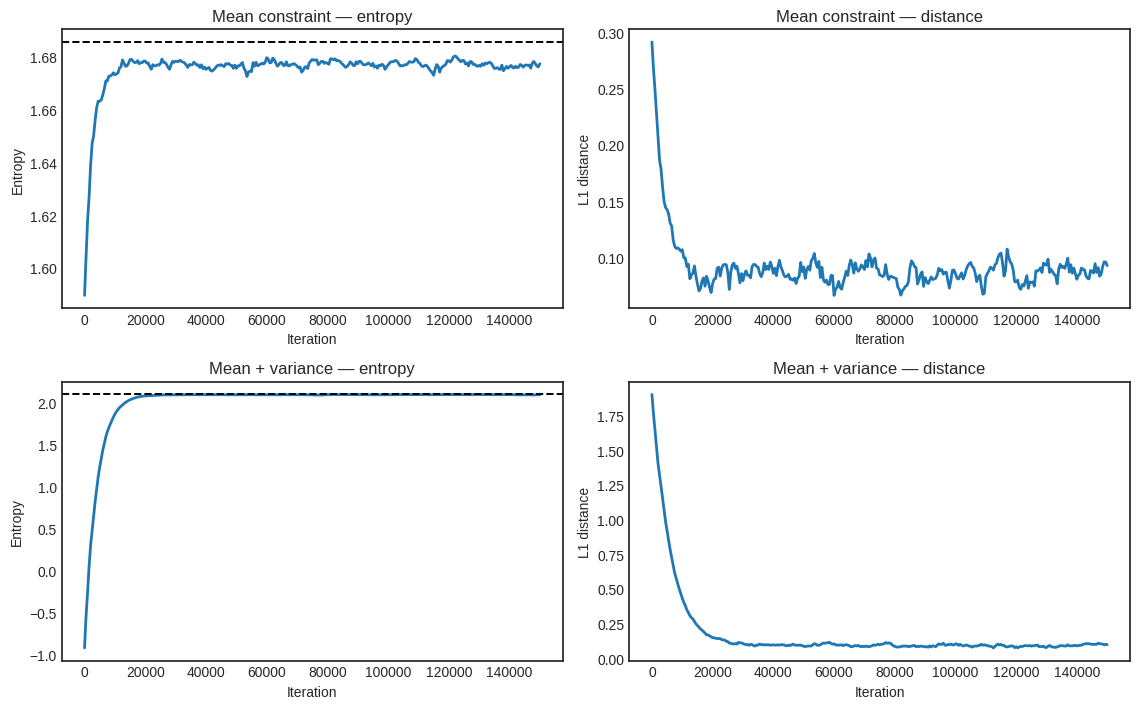

In [24]:
# ============================================================
# CONVERGENCE DIAGNOSTICS
# ============================================================


fig, axes = plt.subplots(
    2,
    2,
    figsize=(11.5, 7.2),
)


trace = result_mean["trace"]

axes[0, 0].plot(
    trace["iteration"],
    trace["entropy"],
    linewidth=2.0,
)

axes[0, 0].axhline(
    entropy_density(qstar_mean),
    color="black",
    linestyle="--",
    linewidth=1.4,
)

axes[0, 0].set(
    title="Mean constraint — entropy",
    xlabel="Iteration",
    ylabel="Entropy",
)


axes[0, 1].plot(
    trace["iteration"],
    trace["L1"],
    linewidth=2.0,
)

axes[0, 1].set(
    title="Mean constraint — distance",
    xlabel="Iteration",
    ylabel="L1 distance",
)


trace = result_mv["trace"]

axes[1, 0].plot(
    trace["iteration"],
    trace["entropy"],
    linewidth=2.0,
)

axes[1, 0].axhline(
    entropy_density(qstar_mv),
    color="black",
    linestyle="--",
    linewidth=1.4,
)

axes[1, 0].set(
    title="Mean + variance — entropy",
    xlabel="Iteration",
    ylabel="Entropy",
)


axes[1, 1].plot(
    trace["iteration"],
    trace["L1"],
    linewidth=2.0,
)

axes[1, 1].set(
    title="Mean + variance — distance",
    xlabel="Iteration",
    ylabel="L1 distance",
)


for ax in axes.flat:
    ax.grid(False)


fig.tight_layout()

plt.show()

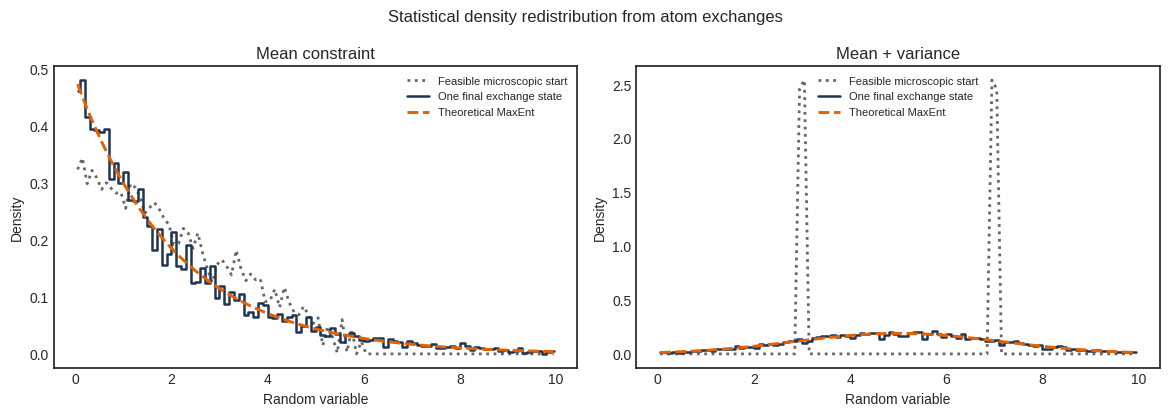

In [25]:
# ============================================================
# DENSITY VIEW OF ACTUAL MICROSCOPIC ENDPOINTS
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.2))

axes[0].plot(centers, density_curve(q0_mean), ":", color="0.40", linewidth=2.0,
             label="Feasible microscopic start")
axes[0].step(centers, density_curve(q_gme_mean), where="mid", linewidth=1.8,
             color="#1f3552", label="One final exchange state")
axes[0].plot(centers, density_curve(qstar_mean), "--", color="#e66101",
             linewidth=2.1, label="Theoretical MaxEnt")
axes[0].set_title("Mean constraint")

axes[1].plot(centers, density_curve(q0_mv), ":", color="0.40", linewidth=2.0,
             label="Feasible microscopic start")
axes[1].step(centers, density_curve(q_gme_mv), where="mid", linewidth=1.8,
             color="#1f3552", label="One final exchange state")
axes[1].plot(centers, density_curve(qstar_mv), "--", color="#e66101",
             linewidth=2.1, label="Theoretical MaxEnt")
axes[1].set_title("Mean + variance")

for axis in axes:
    axis.set(xlabel="Random variable", ylabel="Density")
    axis.legend(frameon=False, fontsize=8)
    axis.grid(False)
fig.suptitle("Statistical density redistribution from atom exchanges")
fig.tight_layout()
plt.show()


## Connectivity evidence and interpretation

The positive count-changing rates, substantial L1 movement from each deliberately non-MaxEnt start, occupation of all six die labels at recorded checkpoints, and convergence of entropy/distance traces provide empirical evidence that these configured chains explore the relevant component. They do **not** prove irreducibility for every finite moment fiber.

The mechanism is sampling, not optimization: the stationary microscopic law is uniform because the proposal is symmetric, while the count-level concentration near MaxEnt arises from the multinomial number of microscopic realizations of each macrostate.

## Finite-population sampling with unequal inclusion probabilities

The analogous finite-population experiment uses $N=6$, $n=3$, and

$$
\pi=(0.25,0.35,0.45,0.55,0.65,0.75), \qquad \sum_i\pi_i=3.
$$

The empirical chain starts from the package's ordered-systematic/Madow GFS design and applies the configured number of genuine `Design.exchange()` calls. Every valid exchange is accepted solely because it preserves the imposed constraints. Entropy is measured afterward; it is never an acceptance or stopping criterion.

There are only $\binom{6}{3}=20$ samples, so the conditional-Poisson MaxEnt distribution can also be solved independently. It remains a **theoretical benchmark**, not a `Design` manufactured from analytical probabilities and not the mechanism that creates the exchanged state.

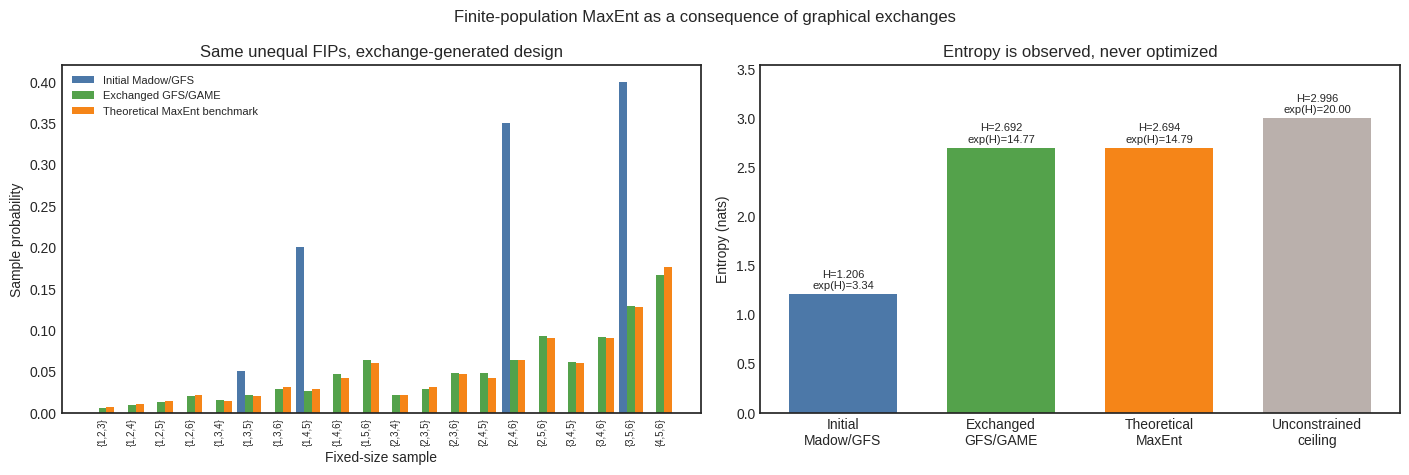

,Design,Entropy,Effective support,Active samples,Maximum FIP error
0,Initial Madow/GFS,1.20562823,3.3389,4,1.110e-16
1,Exchanged GFS/GAME,2.69232133,14.7659,20,1.110e-16
2,Theoretical unequal-FIP MaxEnt benchmark,2.69402759,14.7911,20,1.057e-12


In [26]:
from itertools import combinations
from scipy.optimize import root as scipy_root
from scipy.special import logsumexp as scipy_logsumexp

from prescribed_sip.methods.package_gfs import initial_design, seeded_package

finite_N, finite_n = 6, 3
finite_pi = np.array([0.25, 0.35, 0.45, 0.55, 0.65, 0.75])
assert np.isclose(finite_pi.sum(), finite_n, rtol=0.0, atol=1e-15)

finite_samples = np.asarray(
    list(combinations(range(finite_N), finite_n)), dtype=np.int64
)
finite_incidence = np.zeros((len(finite_samples), finite_N), dtype=float)
for sample_index, sample in enumerate(finite_samples):
    finite_incidence[sample_index, sample] = 1.0
assert len(finite_samples) == 20


def fip_from_probability_mass(mass, N):
    fip = np.zeros(N, dtype=float)
    for sample, probability in mass.items():
        fip[np.asarray(sample, dtype=np.int64)] += probability
    return fip


def probability_vector_from_mass(mass):
    return np.array(
        [mass.get(tuple(sample), 0.0) for sample in finite_samples],
        dtype=float,
    )


def finite_entropy(probability):
    positive = probability > 0
    return float(-np.sum(probability[positive] * np.log(probability[positive])))


finite_settings = SETTINGS["finite_population"]
finite_coords = np.column_stack([np.arange(finite_N), np.zeros(finite_N)])
with seeded_package(finite_settings["seed"]):
    finite_gfs_design = initial_design(finite_pi, finite_coords)

finite_exchange_result = run_design_exchanges(
    finite_gfs_design,
    finite_pi,
    exchanges=finite_settings["exchanges"],
    seed=finite_settings["seed"],
    checkpoint_every=finite_settings["checkpoint_every"],
    partitions=finite_settings["partitions"],
    pull_strategy=finite_settings["pull_strategy"],
    exchange_coef=finite_settings["exchange_coef"],
)
finite_exchanged_design = finite_exchange_result.final_design
finite_exchange_trace = pd.DataFrame(
    [diagnostic.__dict__ for diagnostic in finite_exchange_result.trace]
)

finite_initial_mass = design_probability_mass(finite_gfs_design)
finite_exchanged_mass = design_probability_mass(finite_exchanged_design)
finite_initial_probability = probability_vector_from_mass(finite_initial_mass)
finite_exchanged_probability = probability_vector_from_mass(finite_exchanged_mass)
finite_initial_fip = fip_from_probability_mass(finite_initial_mass, finite_N)
finite_exchanged_fip = fip_from_probability_mass(finite_exchanged_mass, finite_N)
np.testing.assert_allclose(finite_initial_fip, finite_pi, rtol=0.0, atol=1e-12)
np.testing.assert_allclose(finite_exchanged_fip, finite_pi, rtol=0.0, atol=1e-12)

# Independent conditional-Poisson benchmark. One multiplier is fixed because
# a common shift leaves a fixed-size sample distribution unchanged.
def finite_maxent_probability(theta):
    logits = finite_incidence[:, :-1] @ theta
    return np.exp(logits - scipy_logsumexp(logits))


def finite_maxent_residual(theta):
    probability = finite_maxent_probability(theta)
    return (finite_incidence.T @ probability - finite_pi)[:-1]


finite_solution = scipy_root(
    finite_maxent_residual, np.zeros(finite_N - 1, dtype=float)
)
finite_theoretical_probability = finite_maxent_probability(finite_solution.x)
finite_theoretical_fip = finite_incidence.T @ finite_theoretical_probability
finite_theoretical_fip_error = float(
    np.max(np.abs(finite_theoretical_fip - finite_pi))
)
assert finite_solution.success
assert finite_theoretical_fip_error < 1e-10

finite_initial_entropy = finite_entropy(finite_initial_probability)
finite_exchanged_entropy = finite_entropy(finite_exchanged_probability)
finite_theoretical_entropy = finite_entropy(finite_theoretical_probability)
finite_entropy_ceiling = float(np.log(len(finite_samples)))
assert finite_theoretical_entropy > finite_initial_entropy
assert finite_theoretical_entropy <= finite_entropy_ceiling + 1e-12

finite_population = {
    "N": finite_N,
    "n": finite_n,
    "prescribed_fip": finite_pi.copy(),
    "number_of_samples": len(finite_samples),
    "exchange_count": int(finite_settings["exchanges"]),
    "initial_support_size": int(np.count_nonzero(finite_initial_probability > 1e-12)),
    "exchanged_support_size": int(np.count_nonzero(finite_exchanged_probability > 1e-12)),
    "theoretical_support_size": int(np.count_nonzero(finite_theoretical_probability > 1e-12)),
    "initial_probability_sum_error": float(abs(finite_initial_probability.sum() - 1.0)),
    "exchanged_probability_sum_error": float(abs(finite_exchanged_probability.sum() - 1.0)),
    "theoretical_probability_sum_error": float(abs(finite_theoretical_probability.sum() - 1.0)),
    "initial_fip_error": float(np.max(np.abs(finite_initial_fip - finite_pi))),
    "exchanged_fip_error": float(np.max(np.abs(finite_exchanged_fip - finite_pi))),
    "theoretical_fip_error": finite_theoretical_fip_error,
    "initial_entropy": finite_initial_entropy,
    "exchanged_entropy": finite_exchanged_entropy,
    "theoretical_entropy": finite_theoretical_entropy,
    "entropy_ceiling": finite_entropy_ceiling,
    "initial_effective_support": float(np.exp(finite_initial_entropy)),
    "exchanged_effective_support": float(np.exp(finite_exchanged_entropy)),
    "theoretical_effective_support": float(np.exp(finite_theoretical_entropy)),
}
results["finite_population"] = finite_population

sample_labels = [
    "{" + ",".join(str(unit + 1) for unit in sample) + "}"
    for sample in finite_samples
]
positions = np.arange(len(finite_samples))
fig, axes = plt.subplots(1, 2, figsize=(14.2, 4.8))

width = 0.27
axes[0].bar(
    positions - width,
    finite_initial_probability,
    width,
    color="#4c78a8",
    label="Initial Madow/GFS",
)
axes[0].bar(
    positions,
    finite_exchanged_probability,
    width,
    color="#54a24b",
    label="Exchanged GFS/GAME",
)
axes[0].bar(
    positions + width,
    finite_theoretical_probability,
    width,
    color="#f58518",
    label="Theoretical MaxEnt benchmark",
)
axes[0].set(
    xticks=positions,
    xticklabels=sample_labels,
    xlabel="Fixed-size sample",
    ylabel="Sample probability",
    title="Same unequal FIPs, exchange-generated design",
)
axes[0].tick_params(axis="x", rotation=90, labelsize=7)
axes[0].legend(frameon=False, fontsize=8)

entropy_labels = [
    "Initial\nMadow/GFS",
    "Exchanged\nGFS/GAME",
    "Theoretical\nMaxEnt",
    "Unconstrained\nceiling",
]
entropy_values = [
    finite_initial_entropy,
    finite_exchanged_entropy,
    finite_theoretical_entropy,
    finite_entropy_ceiling,
]
entropy_colors = ["#4c78a8", "#54a24b", "#f58518", "#bab0ac"]
bars = axes[1].bar(entropy_labels, entropy_values, color=entropy_colors, width=0.68)
axes[1].set(
    ylabel="Entropy (nats)",
    title="Entropy is observed, never optimized",
    ylim=(0.0, finite_entropy_ceiling * 1.18),
)
for bar, entropy_value in zip(bars, entropy_values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.035,
        f"H={entropy_value:.3f}\nexp(H)={np.exp(entropy_value):.2f}",
        ha="center",
        va="bottom",
        fontsize=8,
    )
for axis in axes:
    axis.grid(False)
fig.suptitle("Finite-population MaxEnt as a consequence of graphical exchanges")
fig.tight_layout()
save_figure(fig, "finite_population_maxent", pdf=True)
if SETTINGS["write_outputs"]:
    plt.show()
plt.close(fig)

finite_population_table = pd.DataFrame(
    {
        "sample": sample_labels,
        "initial_Madow_GFS_probability": finite_initial_probability,
        "exchanged_GFS_GAME_probability": finite_exchanged_probability,
        "theoretical_MaxEnt_probability": finite_theoretical_probability,
    }
)
if SETTINGS["write_outputs"]:
    finite_population_table.to_csv(
        output_dir / "finite_population_maxent.csv",
        index=False,
        float_format="%.17g",
    )

display(pd.DataFrame([
    {
        "Design": "Initial Madow/GFS",
        "Entropy": finite_initial_entropy,
        "Effective support": np.exp(finite_initial_entropy),
        "Active samples": finite_population["initial_support_size"],
        "Maximum FIP error": finite_population["initial_fip_error"],
    },
    {
        "Design": "Exchanged GFS/GAME",
        "Entropy": finite_exchanged_entropy,
        "Effective support": np.exp(finite_exchanged_entropy),
        "Active samples": finite_population["exchanged_support_size"],
        "Maximum FIP error": finite_population["exchanged_fip_error"],
    },
    {
        "Design": "Theoretical unequal-FIP MaxEnt benchmark",
        "Entropy": finite_theoretical_entropy,
        "Effective support": np.exp(finite_theoretical_entropy),
        "Active samples": finite_population["theoretical_support_size"],
        "Maximum FIP error": finite_population["theoretical_fip_error"],
    },
]).style.format({
    "Entropy": "{:.8f}",
    "Effective support": "{:.4f}",
    "Maximum FIP error": "{:.3e}",
}))


## Probability-segment view: Madow versus exchanged GFS/GAME

Both panels below are actual package `Design` states with identical prescribed unequal FIPs. The left is the initial ordered-systematic/Madow construction. The right is obtained only by the configured sequence of unconditional `Design.exchange()` operations. Each short vertical segment is a real probability fragment in the corresponding design; no analytical distribution is converted into a `Design`.

The accompanying trace shows entropy and support as observed consequences. Individual exchanges are not required to increase entropy.

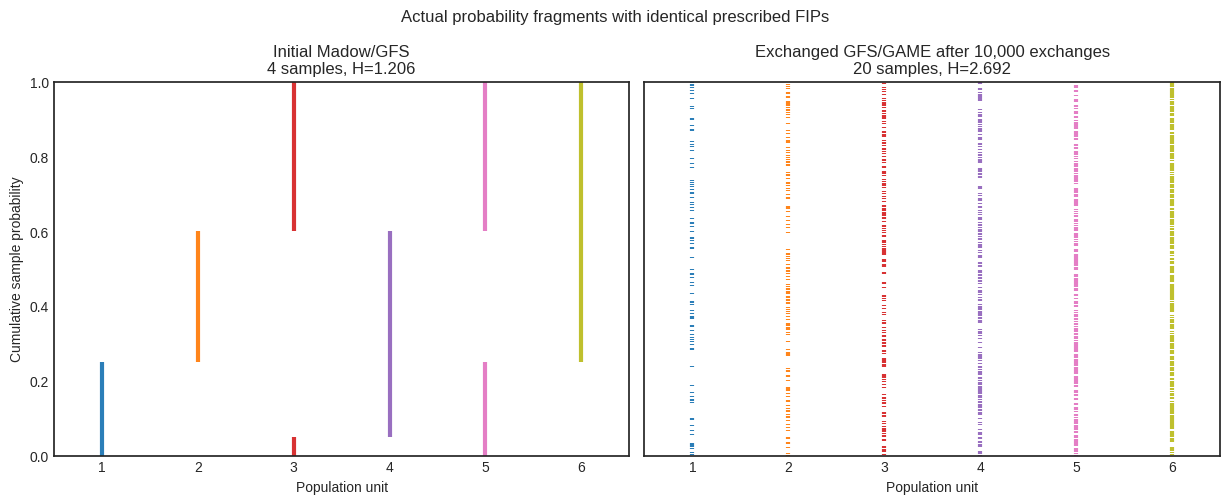

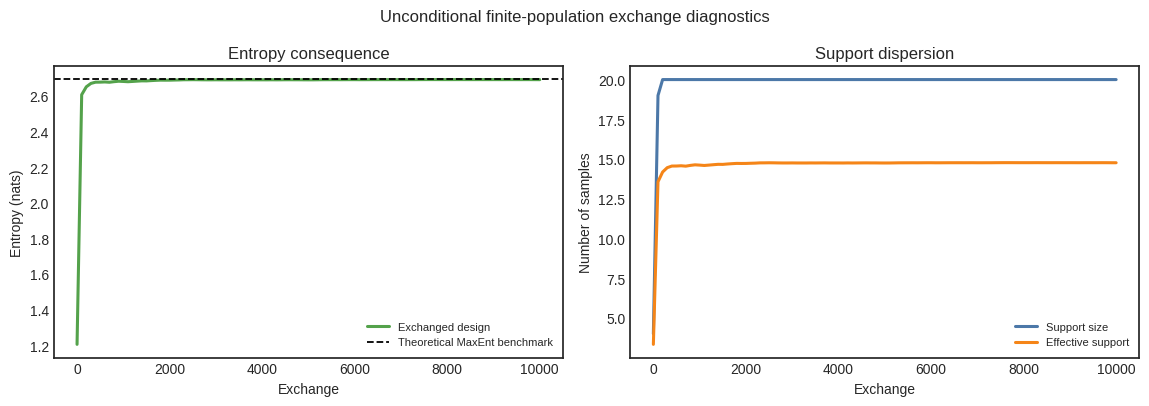

In [27]:
from matplotlib.collections import LineCollection


def draw_probability_segments(design, axis, title):
    """
    Draw the actual probability fragments produced by the GFS design.

    IMPORTANT:
    The internal fragment ordering is reflected vertically so that
    the graphical GFS construction is displayed in the conventional
    probability direction: 0 at the bottom -> 1 at the top.
    """

    fragments = [
        sample
        for heap in design._heaps
        for sample in heap
    ]

    unit_colors = plt.get_cmap("tab10")(
        np.linspace(0.0, 0.8, finite_N)
    )

    by_unit = [[] for _ in range(finite_N)]

    # Internal cumulative position
    lower = 0.0

    for sample in fragments:
        upper = lower + sample.prob

        # ---------------------------------------------------------
        # KEY CORRECTION:
        # Reflect the internal interval [lower, upper]
        # so the GFS picture runs from probability 0 -> 1.
        # ---------------------------------------------------------
        plot_lower = 1.0 - upper
        plot_upper = 1.0 - lower

        for unit in sample.ids:
            by_unit[int(unit)].append(
                [
                    (int(unit) + 1, plot_lower),
                    (int(unit) + 1, plot_upper),
                ]
            )

        lower = upper

    assert np.isclose(
        lower,
        1.0,
        rtol=0.0,
        atol=1e-12,
    )

    for unit, segments in enumerate(by_unit):
        if not segments:
            continue

        axis.add_collection(
            LineCollection(
                segments,
                colors=[unit_colors[unit]],
                linewidths=3.0,   # thicker GFS bars
                alpha=0.95,
            )
        )

    axis.set(
        xlim=(0.5, finite_N + 0.5),
        ylim=(0.0, 1.0),
        xticks=np.arange(1, finite_N + 1),
        yticks=np.linspace(0.0, 1.0, 6),
        xlabel="Population unit",
        title=title,
    )

    # 0 remains physically at bottom, 1 at top.
    # Do NOT use invert_yaxis().
    axis.grid(False)


# ============================================================
# GFS probability-fragment figure
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.4, 5.1),
    sharey=True,
)

draw_probability_segments(
    finite_gfs_design,
    axes[0],
    f"Initial Madow/GFS\n"
    f"{finite_population['initial_support_size']} samples, "
    f"H={finite_initial_entropy:.3f}",
)

draw_probability_segments(
    finite_exchanged_design,
    axes[1],
    f"Exchanged GFS/GAME after "
    f"{finite_settings['exchanges']:,} exchanges\n"
    f"{finite_population['exchanged_support_size']} samples, "
    f"H={finite_exchanged_entropy:.3f}",
)

axes[0].set_ylabel("Cumulative sample probability")

fig.suptitle(
    "Actual probability fragments with identical prescribed FIPs"
)

fig.tight_layout()

save_figure(
    fig,
    "finite_population_segments_madow_vs_exchanged_gfs",
    pdf=True,
)

if SETTINGS["write_outputs"]:
    plt.show()

plt.close(fig)


# ============================================================
# Exchange diagnostics
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11.6, 4.1),
)

axes[0].plot(
    finite_exchange_trace["exchange"],
    finite_exchange_trace["entropy"],
    color="#54a24b",
    linewidth=2.2,
    label="Exchanged design",
)

axes[0].axhline(
    finite_theoretical_entropy,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label="Theoretical MaxEnt benchmark",
)

axes[0].set(
    xlabel="Exchange",
    ylabel="Entropy (nats)",
    title="Entropy consequence",
)

axes[0].legend(
    frameon=False,
    fontsize=8,
)


axes[1].plot(
    finite_exchange_trace["exchange"],
    finite_exchange_trace["support_size"],
    color="#4c78a8",
    linewidth=2.2,
    label="Support size",
)

axes[1].plot(
    finite_exchange_trace["exchange"],
    finite_exchange_trace["effective_support"],
    color="#f58518",
    linewidth=2.2,
    label="Effective support",
)

axes[1].set(
    xlabel="Exchange",
    ylabel="Number of samples",
    title="Support dispersion",
)

axes[1].legend(
    frameon=False,
    fontsize=8,
)

fig.suptitle(
    "Unconditional finite-population exchange diagnostics"
)

fig.tight_layout()

save_figure(
    fig,
    "finite_population_exchange_diagnostics",
    pdf=True,
)

if SETTINGS["write_outputs"]:
    plt.show()

plt.close(fig)


# ============================================================
# Save results
# ============================================================

results["finite_population"] = finite_population

if SETTINGS["write_outputs"]:

    finite_exchange_trace.to_csv(
        output_dir / "finite_population_exchange_trace.csv",
        index=False,
        float_format="%.17g",
    )

    with (
        output_dir / "finite_population_maxent_summary.json"
    ).open(
        "w",
        encoding="utf-8",
    ) as stream:

        json.dump(
            {
                key: (
                    value.tolist()
                    if isinstance(value, np.ndarray)
                    else value
                )
                for key, value in finite_population.items()
            },
            stream,
            indent=2,
        )